In [2]:
import pandas as pd
import numpy as np
from selenium import webdriver
from selenium.webdriver.common.by import By
from selenium.webdriver.common.keys import Keys
from selenium.webdriver.chrome.service import Service
from selenium.webdriver.chrome.options import Options
#from webdriver_manager.chrome import ChromeDriverManager
import matplotlib.pyplot as plt
import seaborn
import re
import warnings
warnings.filterwarnings('ignore')

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("99acres_hyderabad_projects_225.csv")

print("Dataset loaded successfully!")
print("Number of rows and columns:", df.shape)

display(df.head())

Dataset loaded successfully!
Number of rows and columns: (225, 15)


,project_name,status,completion_date,bhk,property_type,location,city,price,area_sqft,builder,rera_number,booking_status,offer,description,raw_details
0,GHR Trivana,New Launch,"Feb, 2030","4, 5",Villa,"Feb, 2030 GHR Trivana NEW BOOKING 4, 5 BHK Vil...",Hyderabad,₹4.05 Cr,NaN,GHR INFRA,NaN,New Booking,NaN,"5 BHK Villa ₹4.62 Cr Spacious and elegant 4,5 ...","New Launch · Completion in Feb, 2030 GHR Triv..."
1,Vision Amnaya,New Launch,"Dec, 2029",3,Apartment,NaN,Hyderabad,₹1.87 - 2.82 Cr,"1,715 - 2,590",Vision Infra Developers Hyderabad,P02400011121,New Booking,NaN,Finest 3 BHK apartments in Khajaguda available...,"New Launch · Completion in Dec, 2029 Vision A..."
2,URBANYARDS SHANGRILA,Under Construction,"Oct, 2030","2, 3",Apartment,"Oct, 2030 URBANYARDS SHANGRILA NEW BOOKING 2, ...",Hyderabad,₹ 87.96 L,"1,466 - 2,903",TempleTree Developers LLP,P02400010486,New Booking,NaN,NaN,"Under Construction · Completion in Oct, 2030 ..."
3,ASBL Broadway,New Launch,"May, 2030",3,Apartment,"May, 2030 ASBL Broadway NEW BOOKING 3 BHK Apar...",Hyderabad,₹ 2.14 - 2.78 Cr,"2,035 - 2,650",ASBL,P02400009684,New Booking,1 OFFER,NaN,"1 OFFER New Launch · Completion in May, 2030 ..."
4,Team4 Aria,New Launch,"Dec, 2030","3, 4",Apartment,"Dec, 2030 Team4 Aria NEW BOOKING 3, 4 BHK Apar...",Hyderabad,₹ 1.25 - 1.9 Cr,"1,655 - 2,650",Team4 Life Spaces (Elite) LLP,P02400010543,New Booking,NaN,NaN,"New Launch · Completion in Dec, 2030 Team4 Ar..."


In [4]:
df

,project_name,status,completion_date,bhk,property_type,location,city,price,area_sqft,builder,rera_number,booking_status,offer,description,raw_details
0,GHR Trivana,New Launch,"Feb, 2030","4, 5",Villa,"Feb, 2030 GHR Trivana NEW BOOKING 4, 5 BHK Vil...",Hyderabad,₹4.05 Cr,NaN,GHR INFRA,NaN,New Booking,NaN,"5 BHK Villa ₹4.62 Cr Spacious and elegant 4,5 ...","New Launch · Completion in Feb, 2030 GHR Triv..."
1,Vision Amnaya,New Launch,"Dec, 2029",3,Apartment,NaN,Hyderabad,₹1.87 - 2.82 Cr,"1,715 - 2,590",Vision Infra Developers Hyderabad,P02400011121,New Booking,NaN,Finest 3 BHK apartments in Khajaguda available...,"New Launch · Completion in Dec, 2029 Vision A..."
2,URBANYARDS SHANGRILA,Under Construction,"Oct, 2030","2, 3",Apartment,"Oct, 2030 URBANYARDS SHANGRILA NEW BOOKING 2, ...",Hyderabad,₹ 87.96 L,"1,466 - 2,903",TempleTree Developers LLP,P02400010486,New Booking,NaN,NaN,"Under Construction · Completion in Oct, 2030 ..."
3,ASBL Broadway,New Launch,"May, 2030",3,Apartment,"May, 2030 ASBL Broadway NEW BOOKING 3 BHK Apar...",Hyderabad,₹ 2.14 - 2.78 Cr,"2,035 - 2,650",ASBL,P02400009684,New Booking,1 OFFER,NaN,"1 OFFER New Launch · Completion in May, 2030 ..."
4,Team4 Aria,New Launch,"Dec, 2030","3, 4",Apartment,"Dec, 2030 Team4 Aria NEW BOOKING 3, 4 BHK Apar...",Hyderabad,₹ 1.25 - 1.9 Cr,"1,655 - 2,650",Team4 Life Spaces (Elite) LLP,P02400010543,New Booking,NaN,NaN,"New Launch · Completion in Dec, 2030 Team4 Ar..."
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
220,Sri Jagathswapna Sparkle Haven,New Launch,"Mar, 2029",4,Villa,"Mar, 2029 Sri Jagathswapna Sparkle Haven NEW B...",Hyderabad,₹ 1.93 - 2.98 Cr,"2,760 - 4,261",Sri Jagathswapna Infra Projects,NaN,New Booking,NaN,NaN,"New Launch · Completion in Mar, 2029 Sri Jaga..."
221,Casagrand Evon,New Launch,"Feb, 2030","3, 4",Apartment,"Feb, 2030 Casagrand Evon NEW BOOKING 3, 4 BHK ...",Hyderabad,₹ 1.72 - 1.73 Cr,"2,075 - 2,850",Casagrand,P02200009350,New Booking,1 OFFER,NaN,"1 OFFER New Launch · Completion in Feb, 2030 ..."
222,Casagrand Crestwood,New Launch,"May, 2028",5,Villa,NaN,Hyderabad,₹ 3.58 - 3.64 Cr,"3,811 - 3,812",Casagrand,NaN,New Booking,1 OFFER,NaN,"1 OFFER New Launch · Completion in May, 2028 ..."
223,Casagrand Hennessy,New Launch,"Apr, 2029","3, 4",Apartment,"Apr, 2029 Casagrand Hennessy NEW BOOKING 3, 4 ...",Hyderabad,₹1.35 - 1.54 Cr,"1,827 - 2,694",Casagrand,P02200010760,New Booking,1 OFFER,4 BHK Apartment ₹1.98 Cr Here are beautifully ...,"1 OFFER New Launch · Completion in Apr, 2029 ..."


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 225 entries, 0 to 224
Data columns (total 15 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   project_name     217 non-null    object
 1   status           217 non-null    object
 2   completion_date  217 non-null    object
 3   bhk              225 non-null    object
 4   property_type    225 non-null    object
 5   location         211 non-null    object
 6   city             225 non-null    object
 7   price            225 non-null    object
 8   area_sqft        211 non-null    object
 9   builder          225 non-null    object
 10  rera_number      174 non-null    object
 11  booking_status   225 non-null    object
 12  offer            57 non-null     object
 13  description      32 non-null     object
 14  raw_details      225 non-null    object
dtypes: object(15)
memory usage: 26.5+ KB


In [7]:
df.isnull().sum()

project_name         8
status               8
completion_date      8
bhk                  0
property_type        0
location            14
city                 0
price                0
area_sqft           14
builder              0
rera_number         51
booking_status       0
offer              168
description        193
raw_details          0
dtype: int64

In [8]:
df.dtypes

project_name       object
status             object
completion_date    object
bhk                object
property_type      object
location           object
city               object
price              object
area_sqft          object
builder            object
rera_number        object
booking_status     object
offer              object
description        object
raw_details        object
dtype: object

In [9]:
import pandas as pd
import numpy as np
import re

# Keep a backup of the original data
df = df.copy()

# --------------------------------------------------
# 1. CLEAN TEXT COLUMNS
# --------------------------------------------------

text_columns = [
    "project_name",
    "status",
    "completion_date",
    "bhk",
    "property_type",
    "location",
    "city",
    "price",
    "area_sqft",
    "builder",
    "rera_number",
    "booking_status",
    "offer",
    "description",
    "raw_details"
]

for col in text_columns:
    if col in df.columns:
        df[col] = df[col].astype("string").str.strip()
        df[col] = df[col].replace(
            ["", "NA", "N/A", "None", "nan", "null", "-"],
            pd.NA
        )

# --------------------------------------------------
# 2. CONVERT PROJECT AND PROPERTY TEXT
# --------------------------------------------------

# Use Unknown only where a categorical value is missing
categorical_columns = [
    "project_name",
    "status",
    "property_type",
    "location",
    "city",
    "builder",
    "booking_status"
]

for col in categorical_columns:
    if col in df.columns:
        df[col] = df[col].fillna("Unknown")

# Preserve missing values in descriptive text
for col in ["description", "raw_details", "offer", "rera_number"]:
    if col in df.columns:
        df[col] = df[col].fillna("Not Available")

# --------------------------------------------------
# 3. CLEAN BHK
# --------------------------------------------------

if "bhk" in df.columns:
    # Extract the first number from values such as
    # "2 BHK", "2-3 BHK", or "3"
    df["bhk"] = pd.to_numeric(
        df["bhk"].astype("string").str.extract(
            r"(\d+)", expand=False
        ),
        errors="coerce"
    ).astype("Int64")

    # Keep unknown BHK values as missing rather than guessing
    # df["bhk"] remains nullable integer

# --------------------------------------------------
# 4. CLEAN AREA IN SQUARE FEET
# --------------------------------------------------

if "area_sqft" in df.columns:
    df["area_sqft"] = pd.to_numeric(
        df["area_sqft"].astype("string").str.replace(
            r"[^0-9.]",
            "",
            regex=True
        ),
        errors="coerce"
    )

    # Fill missing areas with the median
    if df["area_sqft"].notna().any():
        df["area_sqft"] = df["area_sqft"].fillna(
            df["area_sqft"].median()
        )

# --------------------------------------------------
# 5. CLEAN PRICE
# --------------------------------------------------

if "price" in df.columns:
    def convert_price(value):
        if pd.isna(value):
            return np.nan

        value = str(value).strip().lower()
        value = value.replace(",", "").replace("₹", "")
        value = value.replace("rs.", "").replace("rs", "")
        value = value.replace("inr", "").strip()

        # Convert crore/lakh prices to rupees
        match = re.search(
            r"(\d+(?:\.\d+)?)\s*(crores?|cr|lakhs?|lacs?|lakh|lac)\b",
            value
        )

        if match:
            number = float(match.group(1))
            unit = match.group(2)

            if unit.startswith("c") or unit == "cr":
                return number * 10000000

            return number * 100000

        # Handle price ranges such as 80-90 lakh
        numbers = re.findall(r"\d+(?:\.\d+)?", value)

        if numbers:
            return float(numbers[0])

        return np.nan

    df["price"] = df["price"].apply(convert_price)

    # Median imputation is appropriate only if price is
    # represented consistently in the dataset.
    if df["price"].notna().any():
        df["price"] = df["price"].fillna(
            df["price"].median()
        )

# --------------------------------------------------
# 6. CLEAN COMPLETION DATE
# --------------------------------------------------

if "completion_date" in df.columns:
    # Extract year from values such as "December 2027"
    # and store it as a nullable integer.
    year = df["completion_date"].astype("string").str.extract(
        r"((?:19|20|21)\d{2})",
        expand=False
    )

    df["completion_date"] = pd.to_numeric(
        year, errors="coerce"
    ).astype("Int64")

# --------------------------------------------------
# 7. FINAL MISSING-VALUE REPORT
# --------------------------------------------------

print("Missing values after cleaning:")
print(df.isnull().sum())

print("\nFinal data types:")
print(df.dtypes)

print("\nCleaned DataFrame:")
display(df.head(10))

# Save cleaned data
df.to_csv("99acres_hyderabad_cleaned.csv", index=False)

print("\nCleaned dataset saved successfully.")

Missing values after cleaning:
project_name       0
status             0
completion_date    8
bhk                0
property_type      0
location           0
city               0
price              0
area_sqft          0
builder            0
rera_number        0
booking_status     0
offer              0
description        0
raw_details        0
dtype: int64

Final data types:
project_name       string[python]
status             string[python]
completion_date             Int64
bhk                         Int64
property_type      string[python]
location           string[python]
city               string[python]
price                     float64
area_sqft                   Int64
builder            string[python]
rera_number        string[python]
booking_status     string[python]
offer              string[python]
description        string[python]
raw_details        string[python]
dtype: object

Cleaned DataFrame:


,project_name,status,completion_date,bhk,property_type,location,city,price,area_sqft,builder,rera_number,booking_status,offer,description,raw_details
0,GHR Trivana,New Launch,2030,4,Villa,"Feb, 2030 GHR Trivana NEW BOOKING 4, 5 BHK Vil...",Hyderabad,40500000.00,18852550,GHR INFRA,Not Available,New Booking,Not Available,"5 BHK Villa ₹4.62 Cr Spacious and elegant 4,5 ...","New Launch · Completion in Feb, 2030 GHR Triv..."
1,Vision Amnaya,New Launch,2029,3,Apartment,Unknown,Hyderabad,28200000.00,17152590,Vision Infra Developers Hyderabad,P02400011121,New Booking,Not Available,Finest 3 BHK apartments in Khajaguda available...,"New Launch · Completion in Dec, 2029 Vision A..."
2,URBANYARDS SHANGRILA,Under Construction,2030,2,Apartment,"Oct, 2030 URBANYARDS SHANGRILA NEW BOOKING 2, ...",Hyderabad,87.96,14662903,TempleTree Developers LLP,P02400010486,New Booking,Not Available,Not Available,"Under Construction · Completion in Oct, 2030 ..."
3,ASBL Broadway,New Launch,2030,3,Apartment,"May, 2030 ASBL Broadway NEW BOOKING 3 BHK Apar...",Hyderabad,27800000.00,20352650,ASBL,P02400009684,New Booking,1 OFFER,Not Available,"1 OFFER New Launch · Completion in May, 2030 ..."
4,Team4 Aria,New Launch,2030,3,Apartment,"Dec, 2030 Team4 Aria NEW BOOKING 3, 4 BHK Apar...",Hyderabad,19000000.00,16552650,Team4 Life Spaces (Elite) LLP,P02400010543,New Booking,Not Available,Not Available,"New Launch · Completion in Dec, 2030 Team4 Ar..."
5,Ambience Lumina,New Launch,2028,3,Apartment,"Dec, 2028 Ambience Lumina NEW BOOKING 3 BHK Ap...",Hyderabad,18600000.00,18852550,Koncept Ambience,P02400010821,New Booking,Not Available,Not Available,"New Launch · Completion in Dec, 2028 Ambience..."
6,Sark Prime North Meadows Extension,Under Construction,2029,4,Villa,"Oct, 2029 Sark Prime North Meadows Extension N...",Hyderabad,29000000.00,18852550,Sark Projects,Not Available,New Booking,Not Available,Not Available,"Under Construction · Completion in Oct, 2029 ..."
7,Sonthalia Ecorise by Sreenivasa Constructions,New Launch,2029,3,Apartment,"Dec, 2029 Sonthalia Ecorise by Sreenivasa Cons...",Hyderabad,20400000.00,22504695,Sreenivasa Constructions Telangana,P02400010642,New Booking,Not Available,Not Available,"New Launch · Completion in Dec, 2029 Sonthali..."
8,Ark Artha & Ark Aryama,New Launch,2029,3,Villa,"Dec, 2029 Ark Artha & Ark Aryama NEW BOOKING 3...",Hyderabad,30800000.00,34155631,ARK Infra Developers Hyderabad,Not Available,New Booking,Not Available,Not Available,"New Launch · Completion in Dec, 2029 Ark Arth..."
9,EAPL Legacy,New Launch,2030,3,Apartment,"Sep, 2030 EAPL Legacy NEW BOOKING 3, 4 BHK Apa...",Hyderabad,24300000.00,22863348,EAPL Group,P02400011088,New Booking,Not Available,Not Available,"New Launch · Completion in Sep, 2030 EAPL Leg..."



Cleaned dataset saved successfully.


In [10]:
df

,project_name,status,completion_date,bhk,property_type,location,city,price,area_sqft,builder,rera_number,booking_status,offer,description,raw_details
0,GHR Trivana,New Launch,2030,4,Villa,"Feb, 2030 GHR Trivana NEW BOOKING 4, 5 BHK Vil...",Hyderabad,40500000.00,18852550,GHR INFRA,Not Available,New Booking,Not Available,"5 BHK Villa ₹4.62 Cr Spacious and elegant 4,5 ...","New Launch · Completion in Feb, 2030 GHR Triv..."
1,Vision Amnaya,New Launch,2029,3,Apartment,Unknown,Hyderabad,28200000.00,17152590,Vision Infra Developers Hyderabad,P02400011121,New Booking,Not Available,Finest 3 BHK apartments in Khajaguda available...,"New Launch · Completion in Dec, 2029 Vision A..."
2,URBANYARDS SHANGRILA,Under Construction,2030,2,Apartment,"Oct, 2030 URBANYARDS SHANGRILA NEW BOOKING 2, ...",Hyderabad,87.96,14662903,TempleTree Developers LLP,P02400010486,New Booking,Not Available,Not Available,"Under Construction · Completion in Oct, 2030 ..."
3,ASBL Broadway,New Launch,2030,3,Apartment,"May, 2030 ASBL Broadway NEW BOOKING 3 BHK Apar...",Hyderabad,27800000.00,20352650,ASBL,P02400009684,New Booking,1 OFFER,Not Available,"1 OFFER New Launch · Completion in May, 2030 ..."
4,Team4 Aria,New Launch,2030,3,Apartment,"Dec, 2030 Team4 Aria NEW BOOKING 3, 4 BHK Apar...",Hyderabad,19000000.00,16552650,Team4 Life Spaces (Elite) LLP,P02400010543,New Booking,Not Available,Not Available,"New Launch · Completion in Dec, 2030 Team4 Ar..."
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
220,Sri Jagathswapna Sparkle Haven,New Launch,2029,4,Villa,"Mar, 2029 Sri Jagathswapna Sparkle Haven NEW B...",Hyderabad,29800000.00,27604261,Sri Jagathswapna Infra Projects,Not Available,New Booking,Not Available,Not Available,"New Launch · Completion in Mar, 2029 Sri Jaga..."
221,Casagrand Evon,New Launch,2030,3,Apartment,"Feb, 2030 Casagrand Evon NEW BOOKING 3, 4 BHK ...",Hyderabad,17300000.00,20752850,Casagrand,P02200009350,New Booking,1 OFFER,Not Available,"1 OFFER New Launch · Completion in Feb, 2030 ..."
222,Casagrand Crestwood,New Launch,2028,5,Villa,Unknown,Hyderabad,36400000.00,38113812,Casagrand,Not Available,New Booking,1 OFFER,Not Available,"1 OFFER New Launch · Completion in May, 2028 ..."
223,Casagrand Hennessy,New Launch,2029,3,Apartment,"Apr, 2029 Casagrand Hennessy NEW BOOKING 3, 4 ...",Hyderabad,15400000.00,18272694,Casagrand,P02200010760,New Booking,1 OFFER,4 BHK Apartment ₹1.98 Cr Here are beautifully ...,"1 OFFER New Launch · Completion in Apr, 2029 ..."


## UNIVARIATE ANALYSIS

In [11]:
numeric_df = df.select_dtypes(include=[int, float])
numeric_df

,completion_date,bhk,price,area_sqft
0,2030,4,40500000.00,18852550
1,2029,3,28200000.00,17152590
2,2030,2,87.96,14662903
3,2030,3,27800000.00,20352650
4,2030,3,19000000.00,16552650
...,...,...,...,...
220,2029,4,29800000.00,27604261
221,2030,3,17300000.00,20752850
222,2028,5,36400000.00,38113812
223,2029,3,15400000.00,18272694


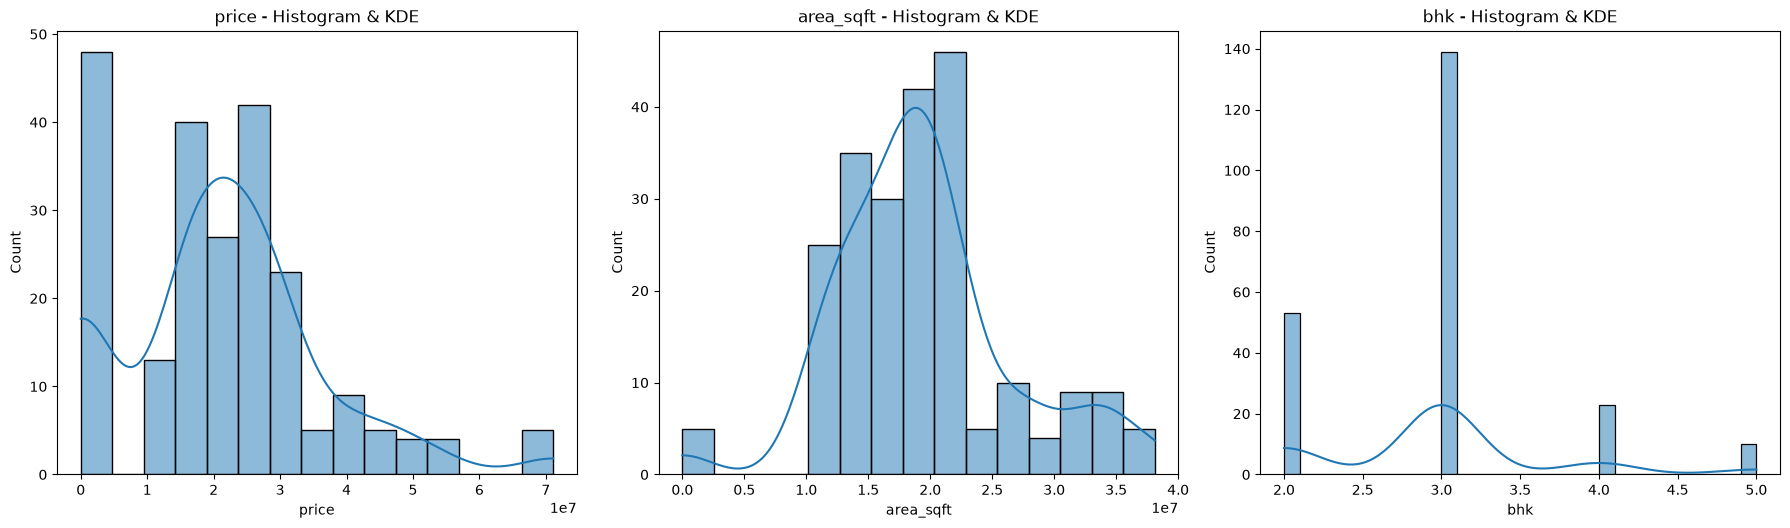

In [12]:
num_cols=['price','area_sqft','bhk']
fig, axes = plt.subplots(3, 3, figsize=(18, 15))
axes = axes.flatten()

for i, col in enumerate(num_cols):
    
    sns.histplot(df[col], kde=True, ax=axes[i], palette='tab10')
    axes[i].set_title(f"{col} - Histogram & KDE")

for j in range(len(num_cols), 9):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

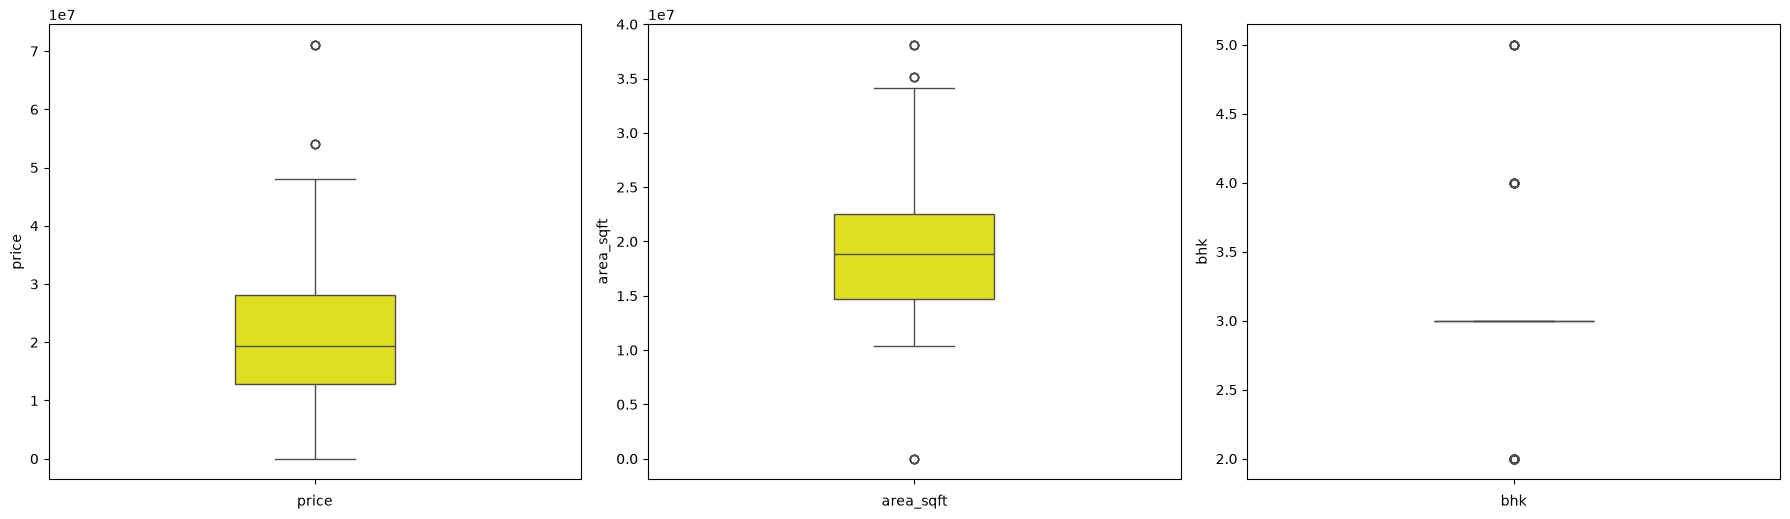

In [13]:
fig, axes = plt.subplots(3, 3, figsize=(18, 15))
axes = axes.flatten()

for i, col in enumerate(num_cols):
    sns.boxplot(y=df[col], ax=axes[i], color="yellow", width=0.3)
    axes[i].set_xlabel(col)
for j in range(len(num_cols), 9):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

In [14]:
for col in df.select_dtypes(include=[int, float]):
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1

    ub = q3 + 1.5 * iqr
    lb = q1 - 1.5 * iqr

    outliers = df[(df[col] > ub) | (df[col] < lb)]
    
    print(f"{col} - Number of outliers: {outliers.shape[0]}")
    print(outliers)

completion_date - Number of outliers: 0
Empty DataFrame
Columns: [project_name, status, completion_date, bhk, property_type, location, city, price, area_sqft, builder, rera_number, booking_status, offer, description, raw_details]
Index: []
bhk - Number of outliers: 86
                           project_name              status  completion_date  \
0                           GHR Trivana          New Launch             2030   
2                  URBANYARDS SHANGRILA  Under Construction             2030   
6    Sark Prime North Meadows Extension  Under Construction             2029   
10                      Candeur Eternia          New Launch             2030   
11                   Sreekalpa Sukhadha          New Launch             2031   
..                                  ...                 ...              ...   
212                           Bliss One  Under Construction             2026   
215                      Casagrand Vybe          New Launch             2029   
219      Th

In [15]:
df.dtypes

project_name       string[python]
status             string[python]
completion_date             Int64
bhk                         Int64
property_type      string[python]
location           string[python]
city               string[python]
price                     float64
area_sqft                   Int64
builder            string[python]
rera_number        string[python]
booking_status     string[python]
offer              string[python]
description        string[python]
raw_details        string[python]
dtype: object

In [16]:
cat_df = df.select_dtypes(
    include=["string", "object", "category"]
)

display(cat_df)

print("Categorical column names:")
print(cat_df.columns.tolist())

,project_name,status,property_type,location,city,builder,rera_number,booking_status,offer,description,raw_details
0,GHR Trivana,New Launch,Villa,"Feb, 2030 GHR Trivana NEW BOOKING 4, 5 BHK Vil...",Hyderabad,GHR INFRA,Not Available,New Booking,Not Available,"5 BHK Villa ₹4.62 Cr Spacious and elegant 4,5 ...","New Launch · Completion in Feb, 2030 GHR Triv..."
1,Vision Amnaya,New Launch,Apartment,Unknown,Hyderabad,Vision Infra Developers Hyderabad,P02400011121,New Booking,Not Available,Finest 3 BHK apartments in Khajaguda available...,"New Launch · Completion in Dec, 2029 Vision A..."
2,URBANYARDS SHANGRILA,Under Construction,Apartment,"Oct, 2030 URBANYARDS SHANGRILA NEW BOOKING 2, ...",Hyderabad,TempleTree Developers LLP,P02400010486,New Booking,Not Available,Not Available,"Under Construction · Completion in Oct, 2030 ..."
3,ASBL Broadway,New Launch,Apartment,"May, 2030 ASBL Broadway NEW BOOKING 3 BHK Apar...",Hyderabad,ASBL,P02400009684,New Booking,1 OFFER,Not Available,"1 OFFER New Launch · Completion in May, 2030 ..."
4,Team4 Aria,New Launch,Apartment,"Dec, 2030 Team4 Aria NEW BOOKING 3, 4 BHK Apar...",Hyderabad,Team4 Life Spaces (Elite) LLP,P02400010543,New Booking,Not Available,Not Available,"New Launch · Completion in Dec, 2030 Team4 Ar..."
...,...,...,...,...,...,...,...,...,...,...,...
220,Sri Jagathswapna Sparkle Haven,New Launch,Villa,"Mar, 2029 Sri Jagathswapna Sparkle Haven NEW B...",Hyderabad,Sri Jagathswapna Infra Projects,Not Available,New Booking,Not Available,Not Available,"New Launch · Completion in Mar, 2029 Sri Jaga..."
221,Casagrand Evon,New Launch,Apartment,"Feb, 2030 Casagrand Evon NEW BOOKING 3, 4 BHK ...",Hyderabad,Casagrand,P02200009350,New Booking,1 OFFER,Not Available,"1 OFFER New Launch · Completion in Feb, 2030 ..."
222,Casagrand Crestwood,New Launch,Villa,Unknown,Hyderabad,Casagrand,Not Available,New Booking,1 OFFER,Not Available,"1 OFFER New Launch · Completion in May, 2028 ..."
223,Casagrand Hennessy,New Launch,Apartment,"Apr, 2029 Casagrand Hennessy NEW BOOKING 3, 4 ...",Hyderabad,Casagrand,P02200010760,New Booking,1 OFFER,4 BHK Apartment ₹1.98 Cr Here are beautifully ...,"1 OFFER New Launch · Completion in Apr, 2029 ..."


Categorical column names:
['project_name', 'status', 'property_type', 'location', 'city', 'builder', 'rera_number', 'booking_status', 'offer', 'description', 'raw_details']


AttributeError: 'numpy.ndarray' object has no attribute 'pie'

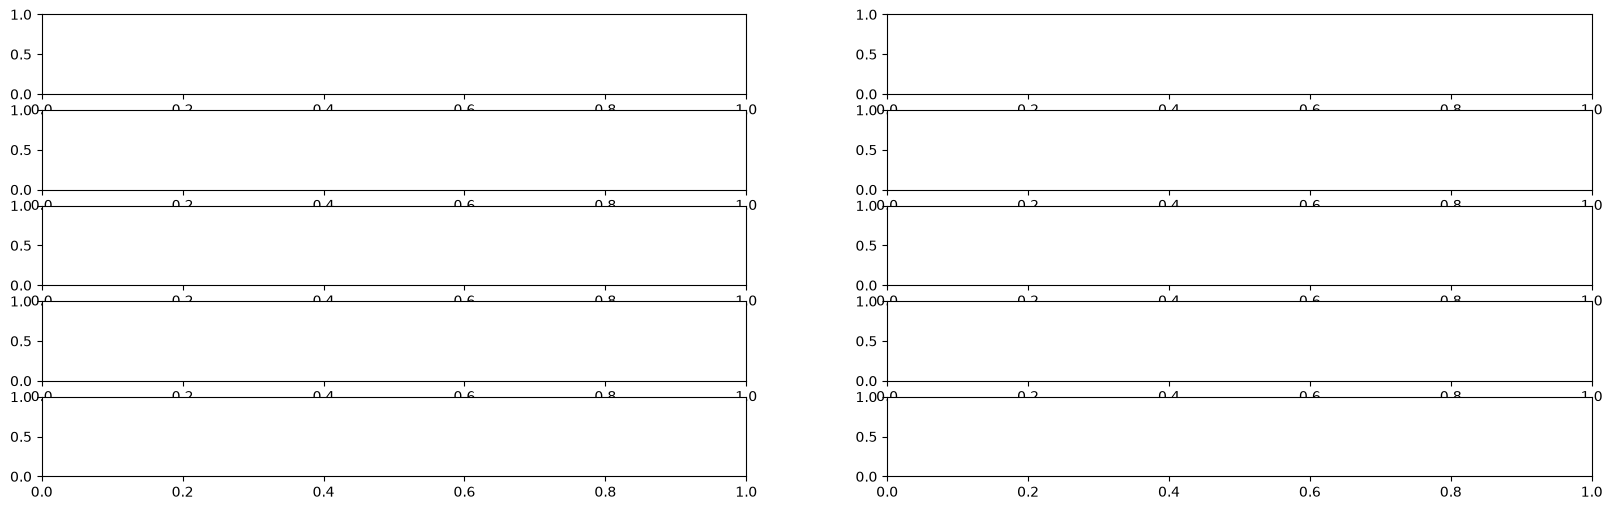

In [17]:
categorical_cols = ['project_name', 'status', 'property_type', 'location', 'city', 'rera_number', 'booking_status', 'offer', 'description', 'raw_details']

fig, axes = plt.subplots(5, 2, figsize=(20, 6))

for i, col in enumerate(categorical_cols):
    top10 = df[col].value_counts().nlargest(10)
    axes[i].pie(top10.values, labels=top10.index, autopct='%1.1f%%', startangle=90)
    axes[i].set_title(f"Top 10 {col}")
plt.tight_layout()
plt.show()

In [ ]:
['project_name', 'status', 'property_type', 'location', 'city', 'builder', 'rera_number', 'booking_status', 'offer', 'description', 'raw_details']

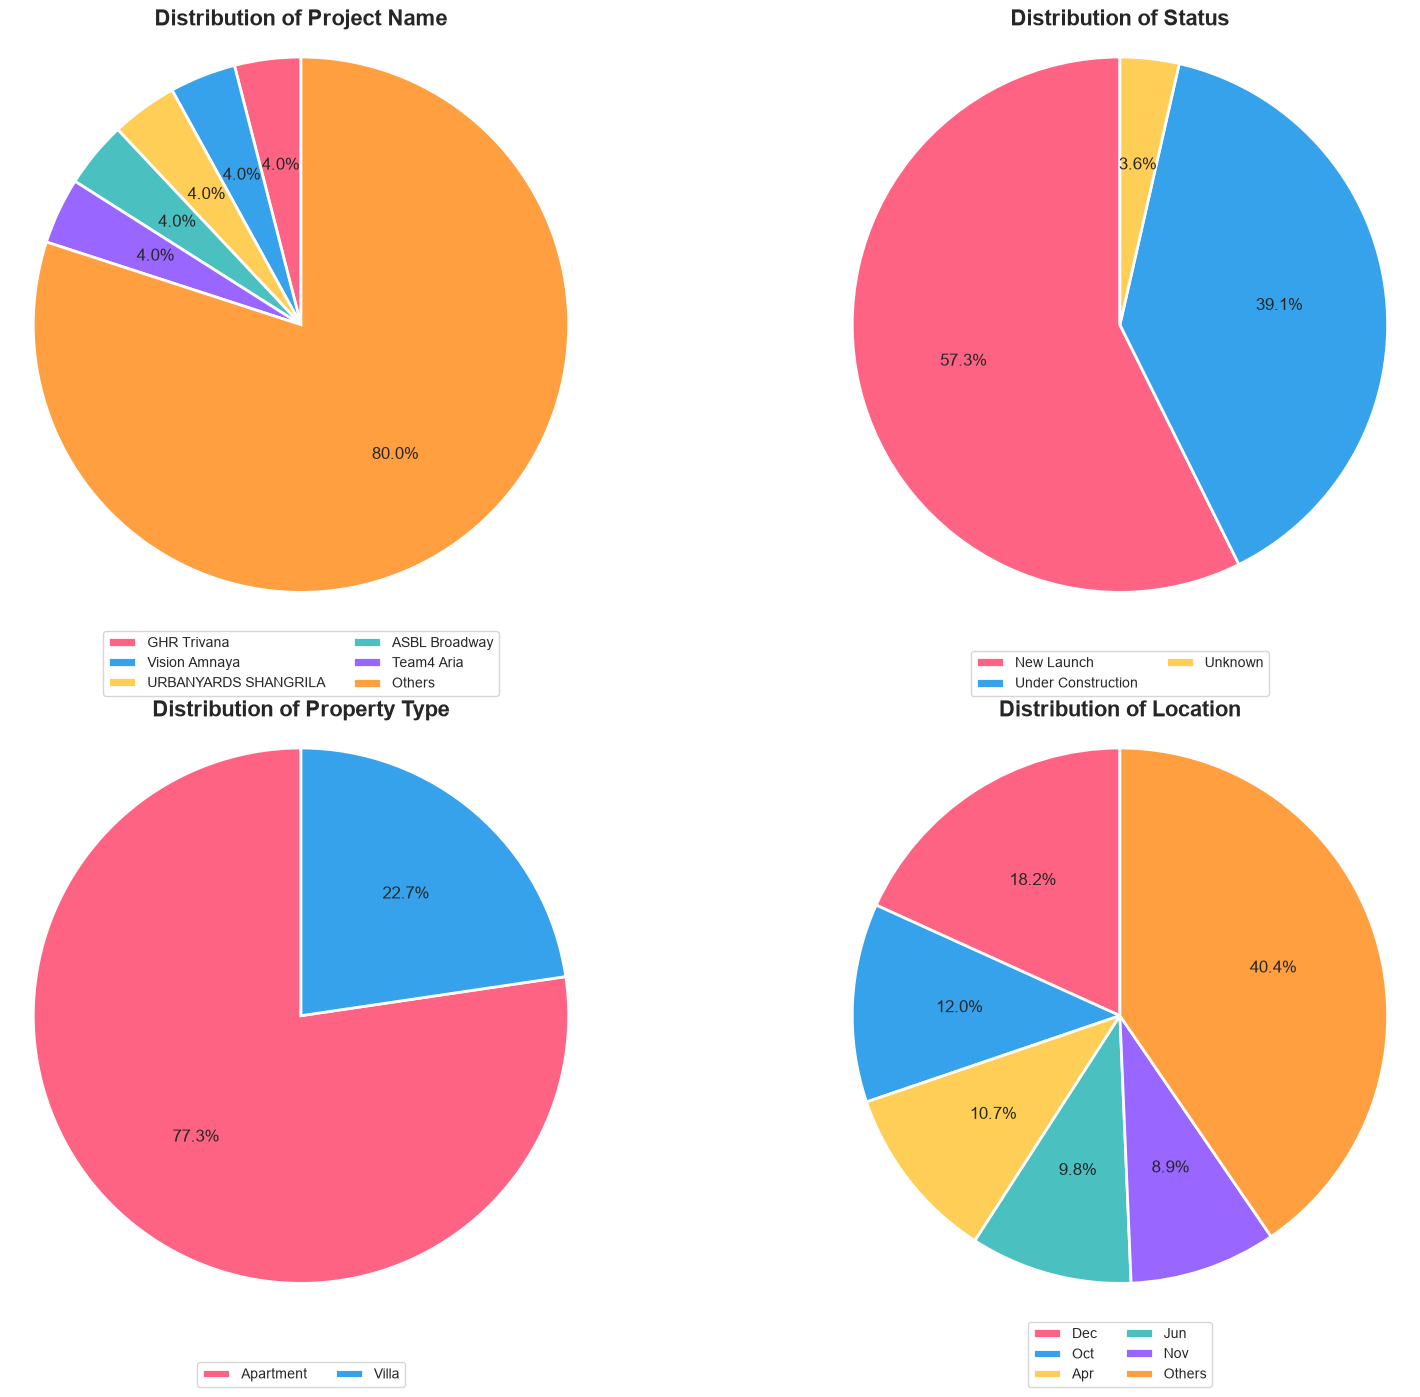

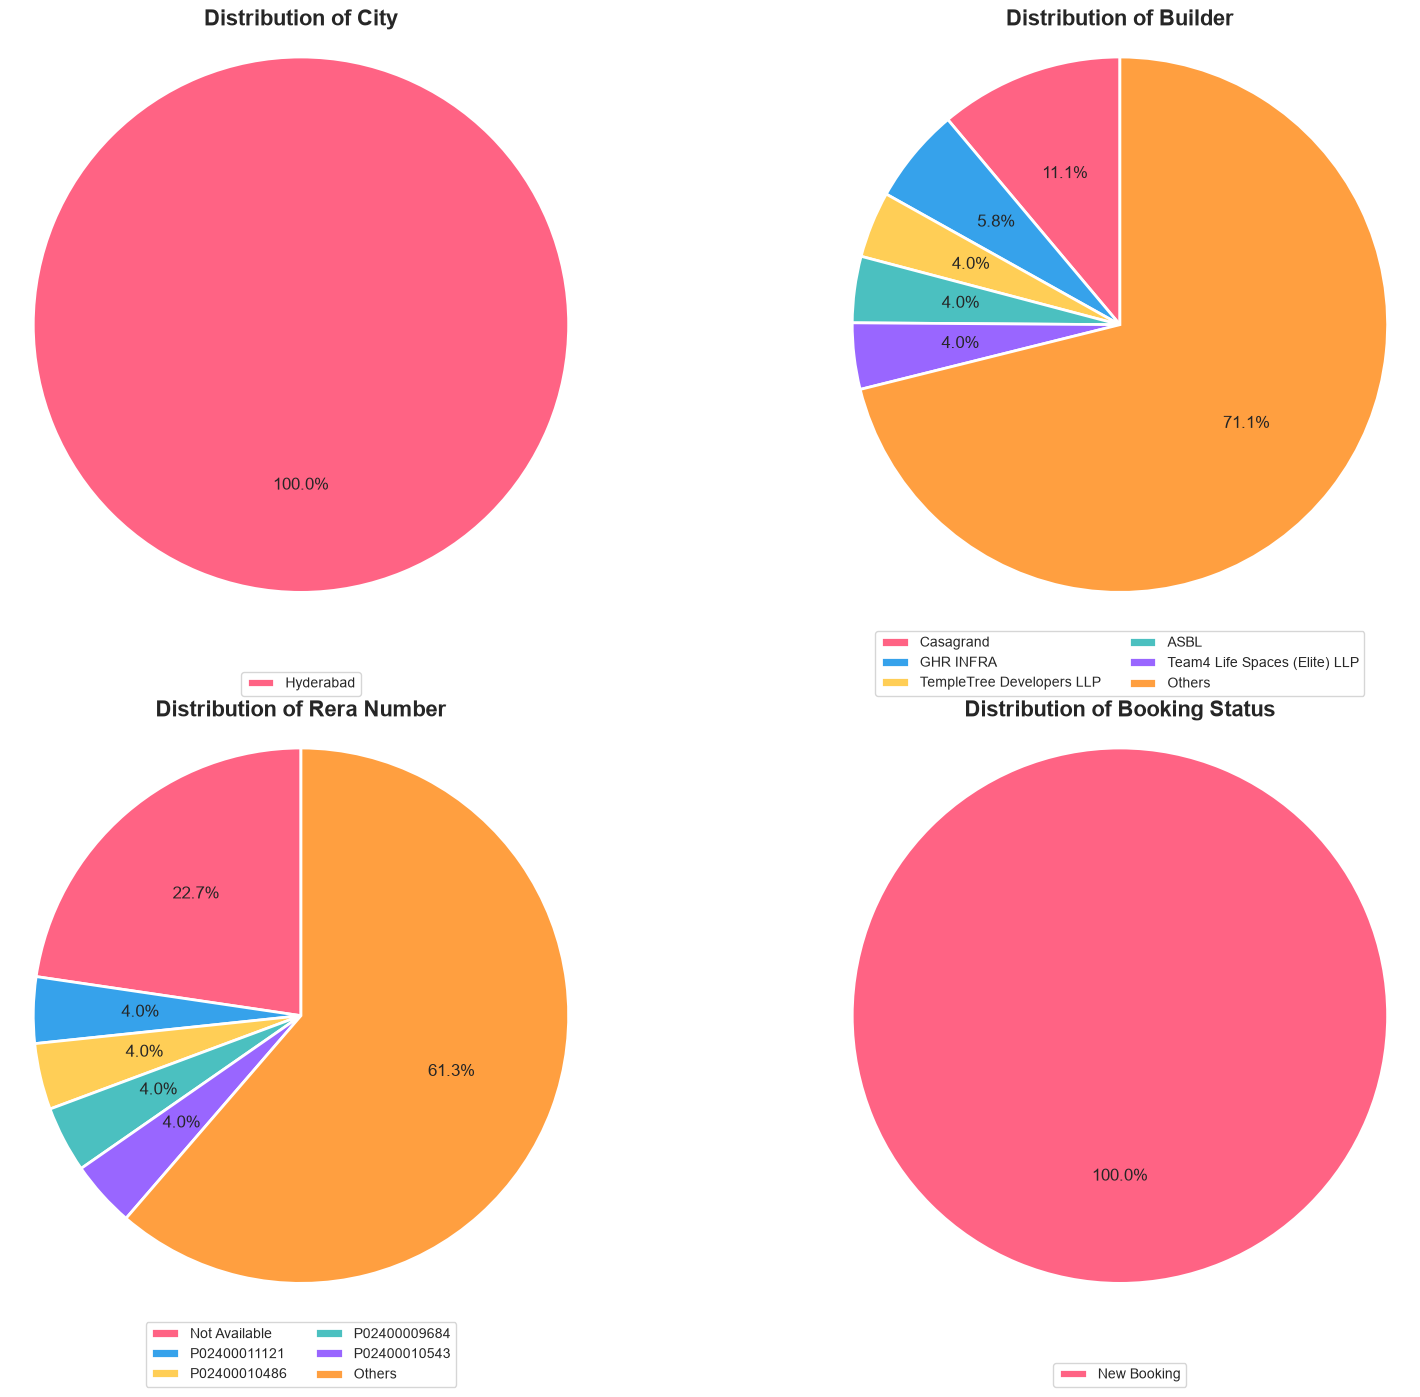

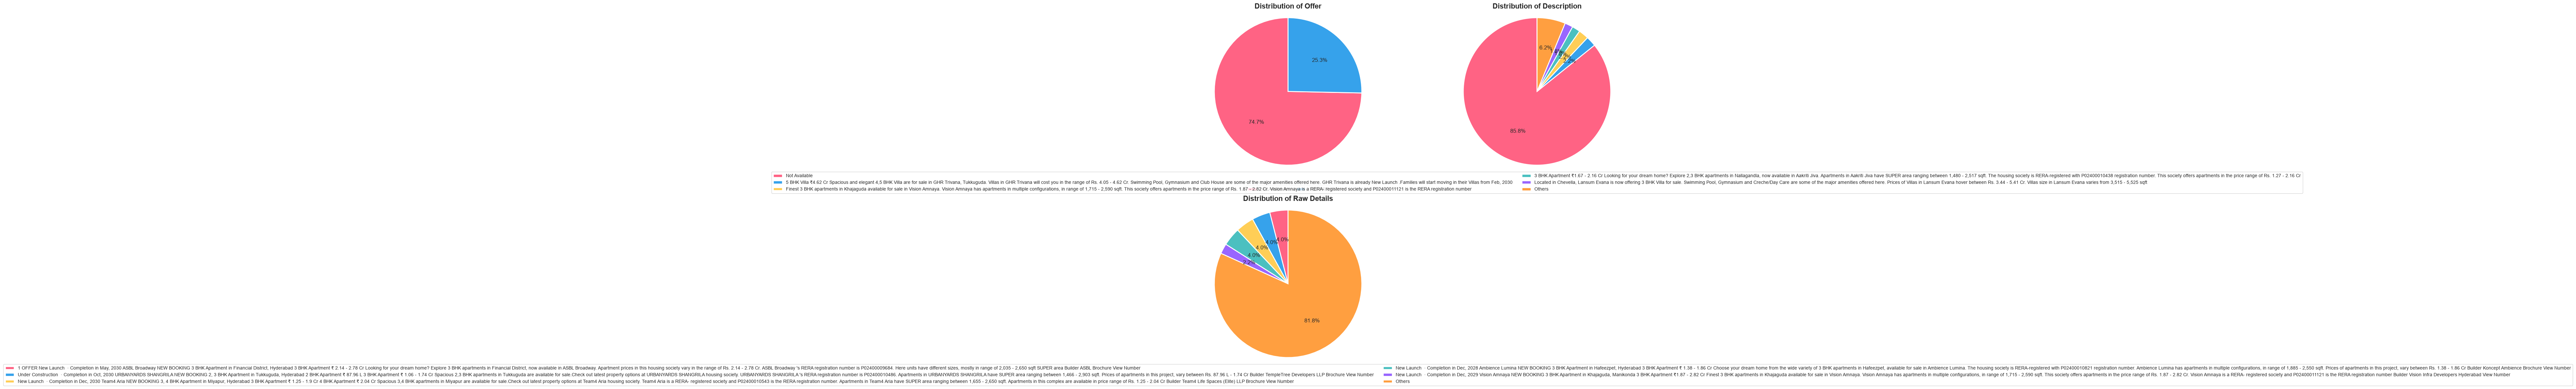

In [116]:
import matplotlib.pyplot as plt

categorical_cols = [
    "project_name", "status", "property_type",
    "location", "city", "builder", "rera_number",
     "booking_status", "offer","description",
    "raw_details"
]

colors = [
    "#FF6384", "#36A2EB", "#FFCE56", "#4BC0C0",
    "#9966FF", "#FF9F40", "#00C49F", "#F06292",
    "#7986CB", "#D4E157", "#26C6DA"
]

for start in range(0, len(categorical_cols), 4):

    cols = categorical_cols[start:start + 4]

    fig, axes = plt.subplots(2, 2, figsize=(18, 14))
    axes = axes.flatten()

    for i, col in enumerate(cols):

        counts = (
            df[col]
            .fillna("Not Available")
            .astype(str)
            .value_counts()
        )

        top = counts.head(5).copy()
        others = counts.iloc[5:].sum()

        if others > 0:
            top["Others"] = others

        wedges, texts, autotexts = axes[i].pie(
            top.values,
            labels=None,
            autopct="%1.1f%%",
            startangle=90,
            colors=colors[:len(top)],
            radius=1.15,
            wedgeprops={"edgecolor": "white", "linewidth": 2}
        )

        axes[i].legend(
            wedges,
            top.index,
            loc="lower center",
            bbox_to_anchor=(0.5, -0.15),
            ncol=2,
            fontsize=10
        )

        axes[i].set_title(
            f"Distribution of {col.replace('_', ' ').title()}",
            fontsize=16,
            fontweight="bold"
        )

    for i in range(len(cols), 4):
        axes[i].axis("off")

    plt.tight_layout()
    plt.show()

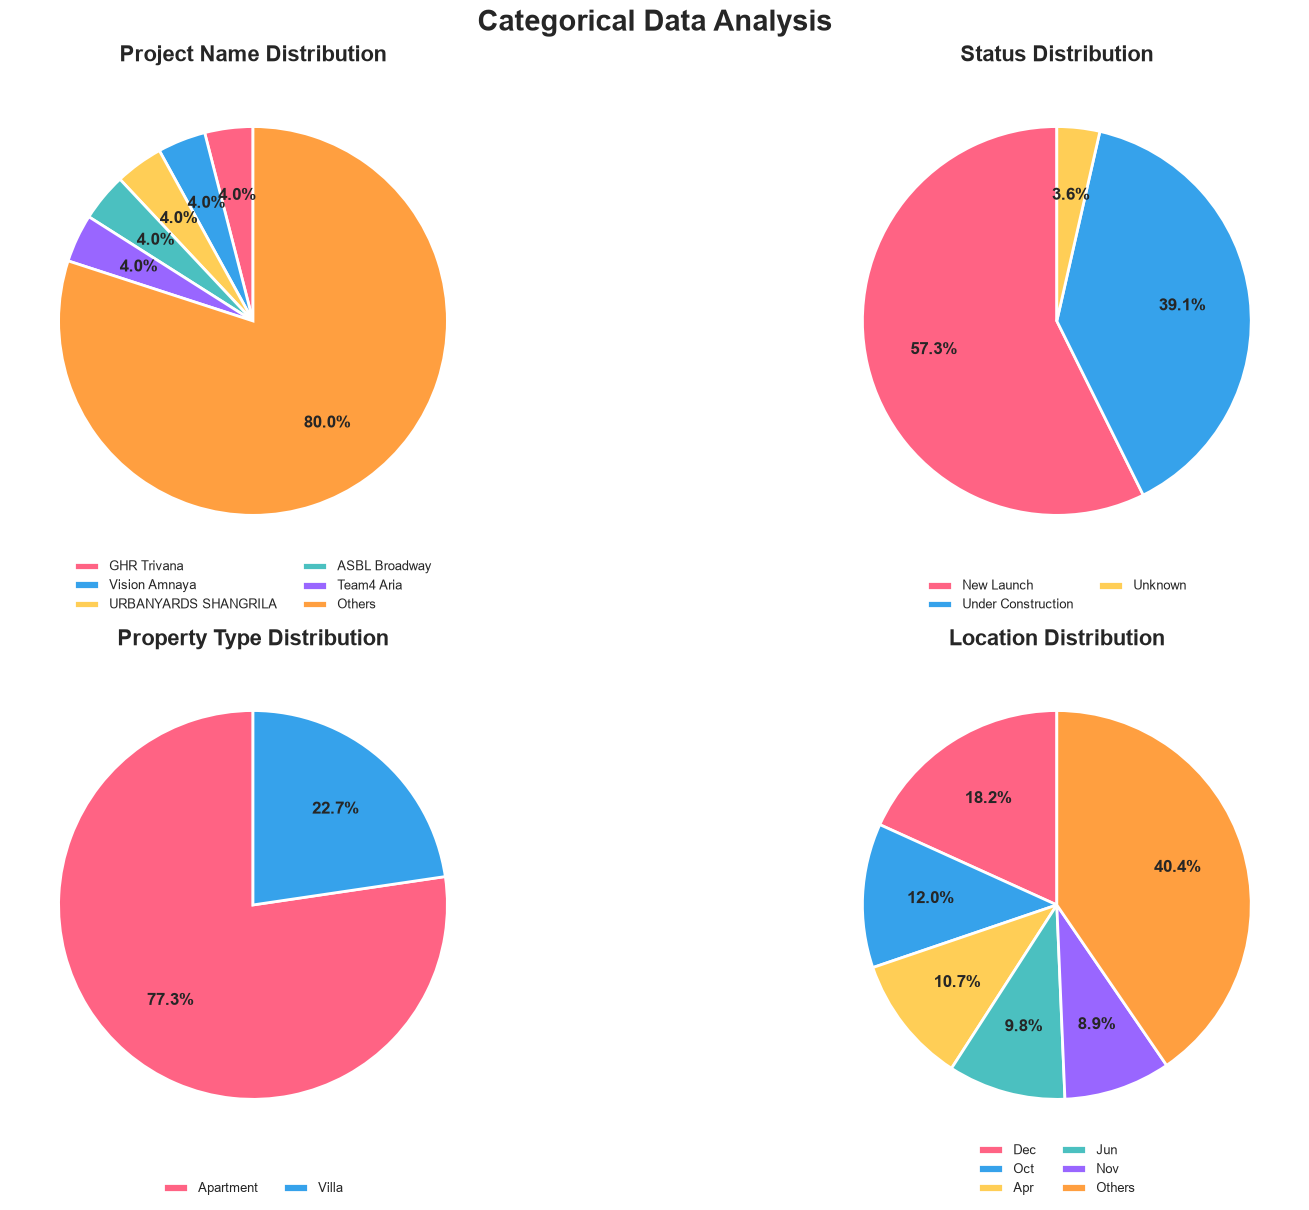

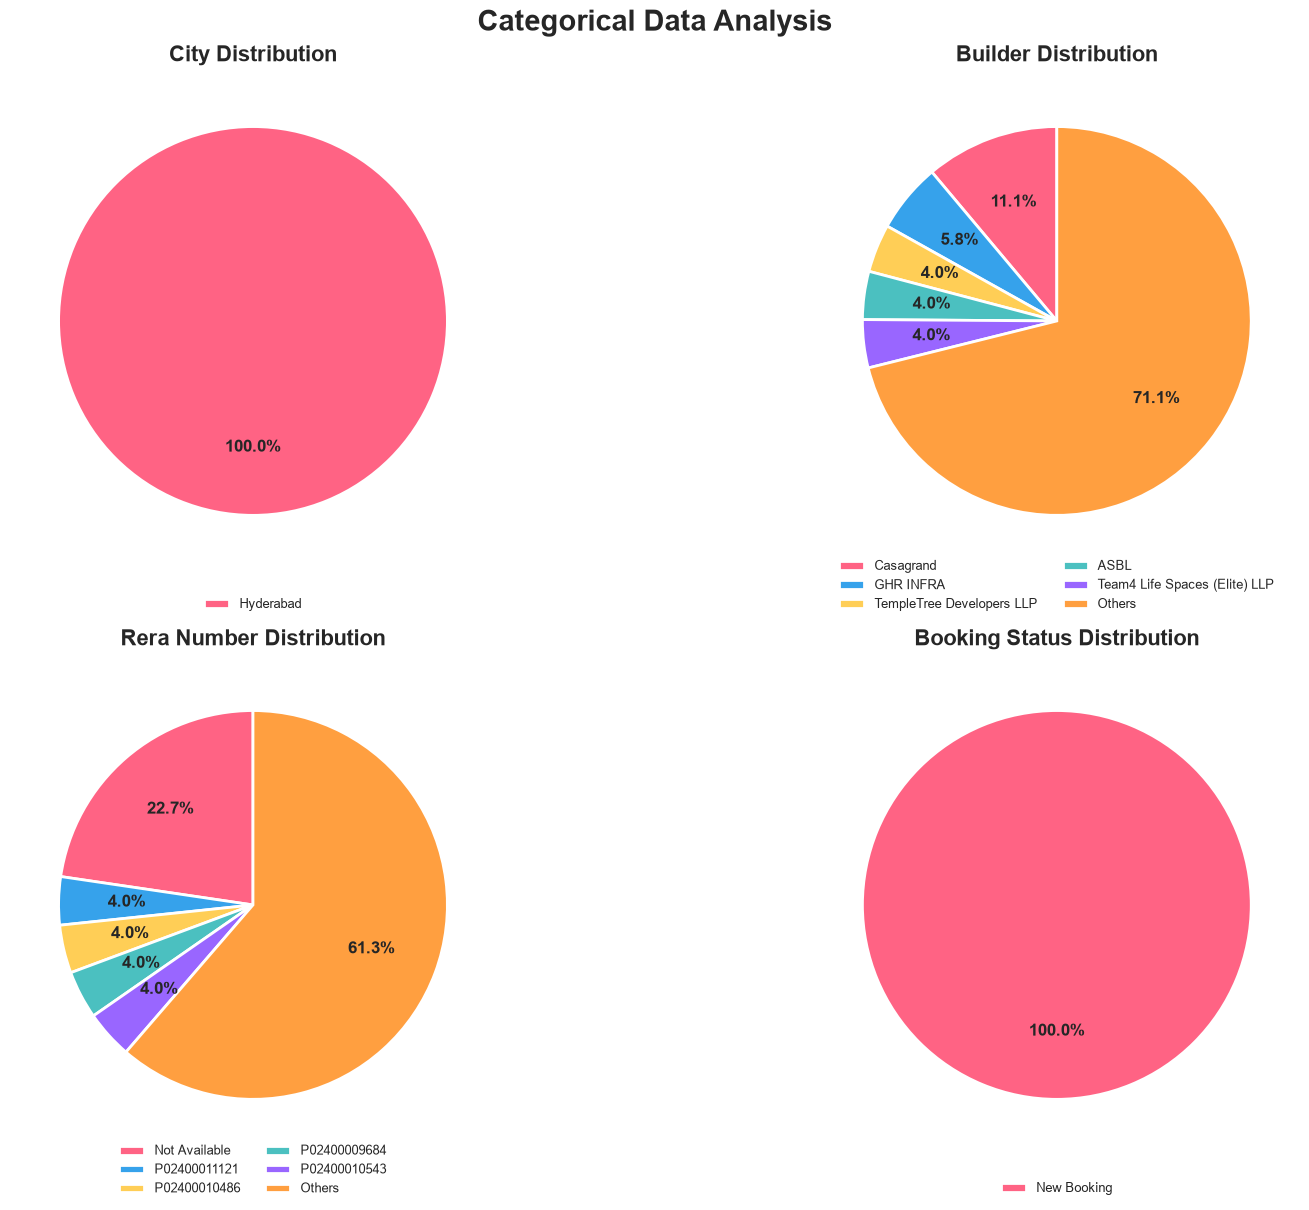

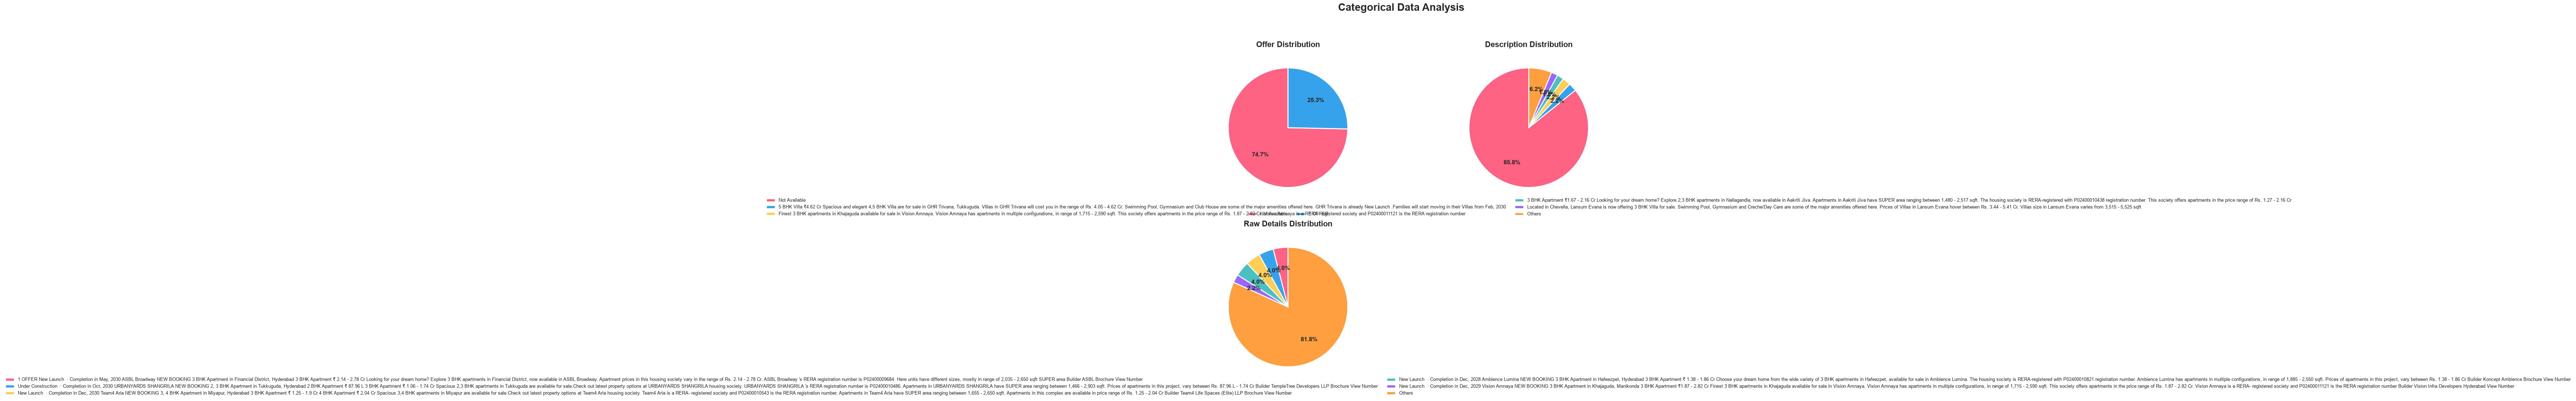

In [117]:
import matplotlib.pyplot as plt
import math

categorical_cols = [
    "project_name", "status", "property_type",
    "location", "city", "builder", "rera_number",
     "booking_status", "offer","description",
    "raw_details"
]

colors = [
    "#FF6384", "#36A2EB", "#FFCE56",
    "#4BC0C0", "#9966FF", "#FF9F40",
    "#00C49F", "#F06292", "#7986CB",
    "#D4E157", "#26C6DA"
]

for start in range(0, len(categorical_cols), 4):

    cols = categorical_cols[start:start + 4]

    fig, axes = plt.subplots(
        2, 2,
        figsize=(16, 12),
        constrained_layout=True
    )
    axes = axes.flatten()

    for i, col in enumerate(cols):

        counts = (
            df[col]
            .fillna("Not Available")
            .astype(str)
            .value_counts()
        )

        top = counts.head(5).copy()
        others = counts.iloc[5:].sum()

        if others > 0:
            top.loc["Others"] = others

        wedges, _, autotexts = axes[i].pie(
            top.values,
            labels=None,
            autopct="%1.1f%%",
            startangle=90,
            colors=colors[:len(top)],
            radius=1.0,
            pctdistance=0.65,
            wedgeprops={
                "edgecolor": "white",
                "linewidth": 2
            },
            textprops={
                "fontsize": 12,
                "fontweight": "bold"
            }
        )

        axes[i].set_title(
            f"{col.replace('_', ' ').title()} Distribution",
            fontsize=16,
            fontweight="bold",
            pad=12
        )

        axes[i].legend(
            wedges,
            top.index,
            loc="lower center",
            bbox_to_anchor=(0.5, -0.12),
            ncol=2,
            fontsize=9,
            frameon=False
        )

        axes[i].set_aspect("equal")

    for j in range(len(cols), 4):
        axes[j].axis("off")

    fig.suptitle(
        "Categorical Data Analysis",
        fontsize=21,
        fontweight="bold"
    )

    plt.show()
    plt.close(fig)

Skipping project_name: too many categories for a pie chart.


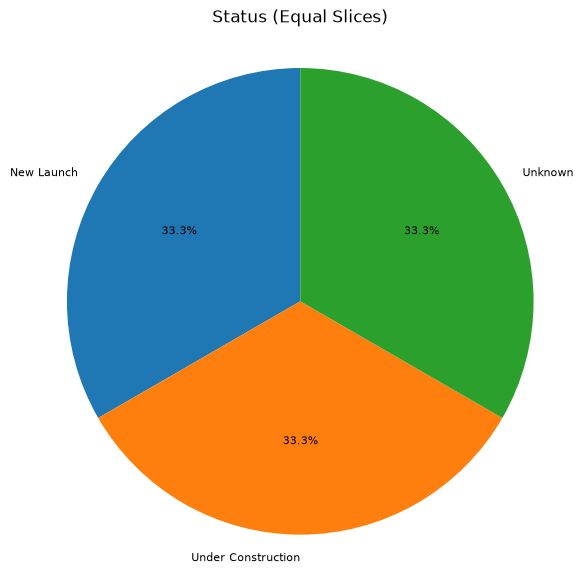

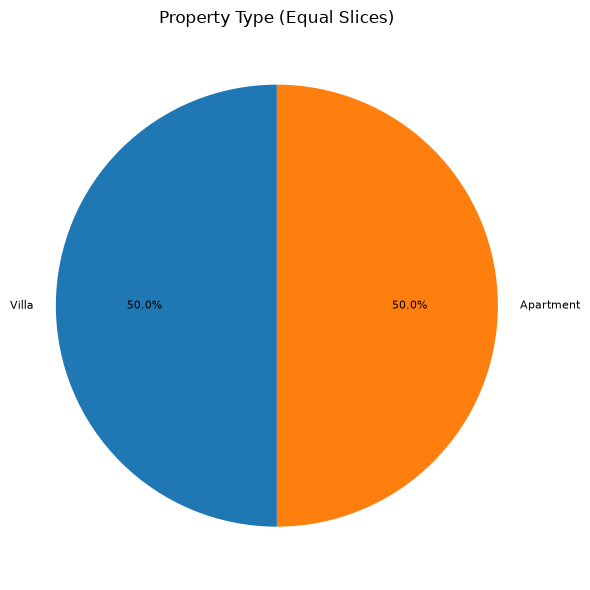

Skipping location: too many categories for a pie chart.


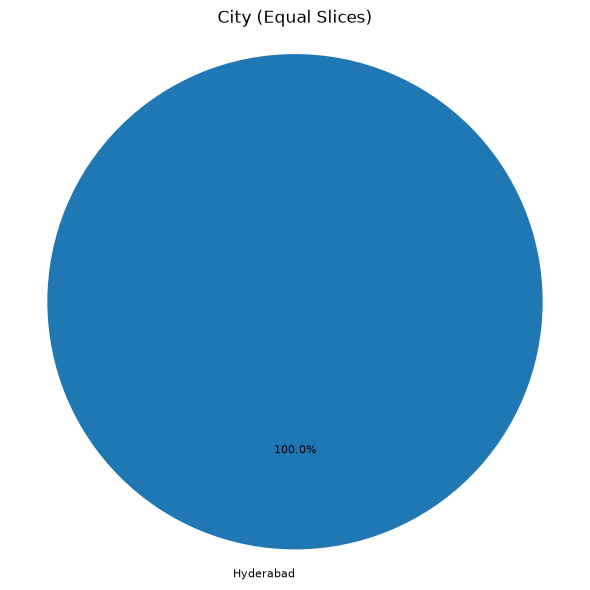

Skipping builder: too many categories for a pie chart.


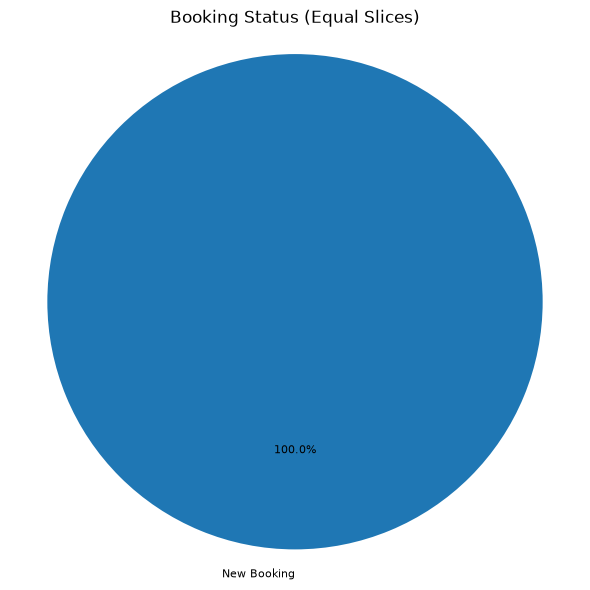

In [112]:
import matplotlib.pyplot as plt

categorical_columns = [
    "project_name",
    "status",
    "property_type",
    "location",
    "city",
    "builder",
    "booking_status"
]

for col in categorical_columns:

    if col not in df.columns:
        continue

    categories = (
        df[col]
        .fillna("Unknown")
        .astype(str)
        .unique()
    )

    # Avoid charts with too many categories
    if len(categories) > 10:
        print(f"Skipping {col}: too many categories for a pie chart.")
        continue

    # Give every category an equal value
    values = [1] * len(categories)

    fig, ax = plt.subplots(figsize=(6, 6))

    ax.pie(
        values,
        labels=categories,
        autopct="%1.1f%%",
        startangle=90,
        textprops={"fontsize": 8}
    )

    ax.set_title(f"{col.replace('_', ' ').title()} (Equal Slices)")
    ax.axis("equal")
    plt.tight_layout()
    plt.show()

## BIVARIATE ANALYSIS


### Categorical VS Categorical columns

### 1. Property Type vs Project Status
Purpose: Compare the number of projects in each status across property types.

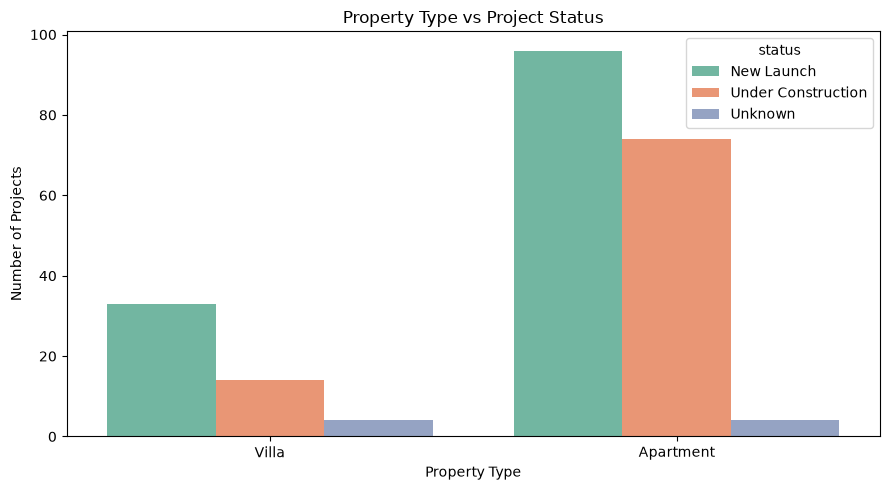

In [42]:

plt.figure(figsize=(9, 5))

sns.countplot(
    data=df,
    x="property_type",
    hue="status",
    palette="Set2"
)

plt.title("Property Type vs Project Status")
plt.xlabel("Property Type")
plt.ylabel("Number of Projects")
plt.tight_layout()
plt.show()


### 2. Location vs Booking Status
Purpose: Compare booking-status categories across different locations

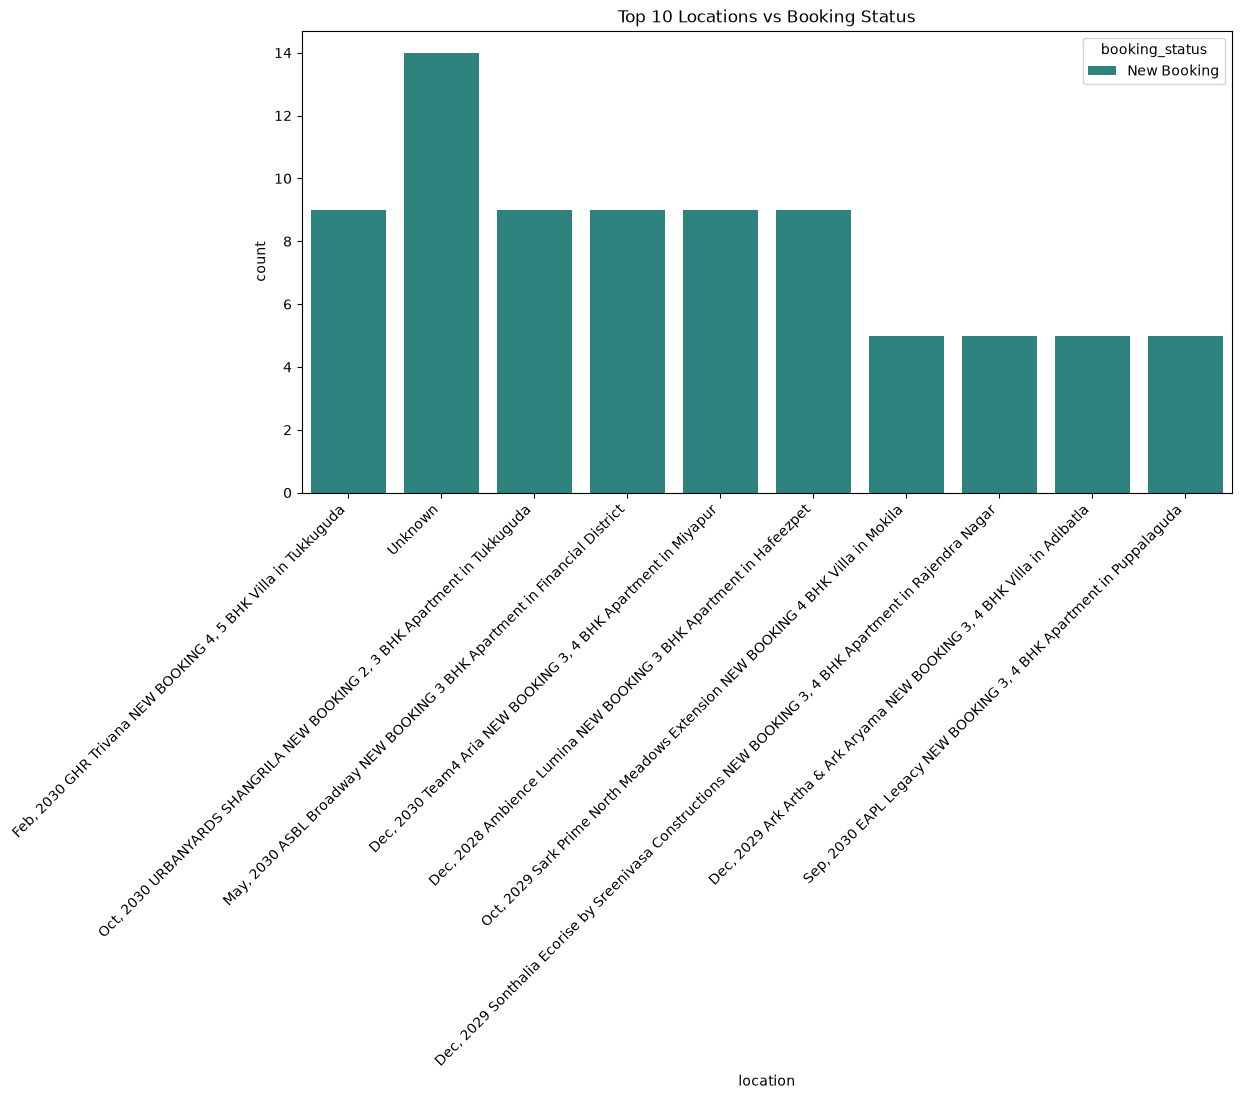

In [43]:

top_locations = df["location"].value_counts().head(10).index
temp = df[df["location"].isin(top_locations)]

plt.figure(figsize=(12, 6))

sns.countplot(
    data=temp,
    x="location",
    hue="booking_status",
    palette="viridis"
)

plt.title("Top 10 Locations vs Booking Status")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


### 3. Builder vs Property Type
Purpose: Compare property types listed by different builders.

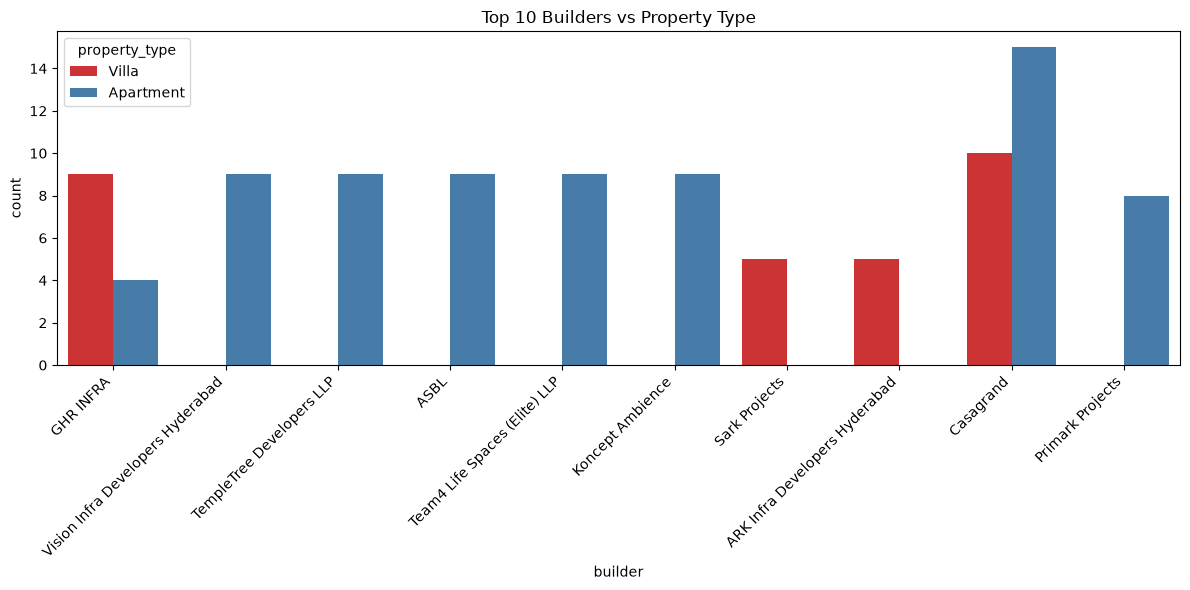

In [44]:

top_builders = df["builder"].value_counts().head(10).index
temp = df[df["builder"].isin(top_builders)]

plt.figure(figsize=(12, 6))

sns.countplot(
    data=temp,
    x="builder",
    hue="property_type",
    palette="Set1"
)

plt.title("Top 10 Builders vs Property Type")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


### 4. Project Status vs Booking Status
Purpose: Check how project status and booking status are distributed together.

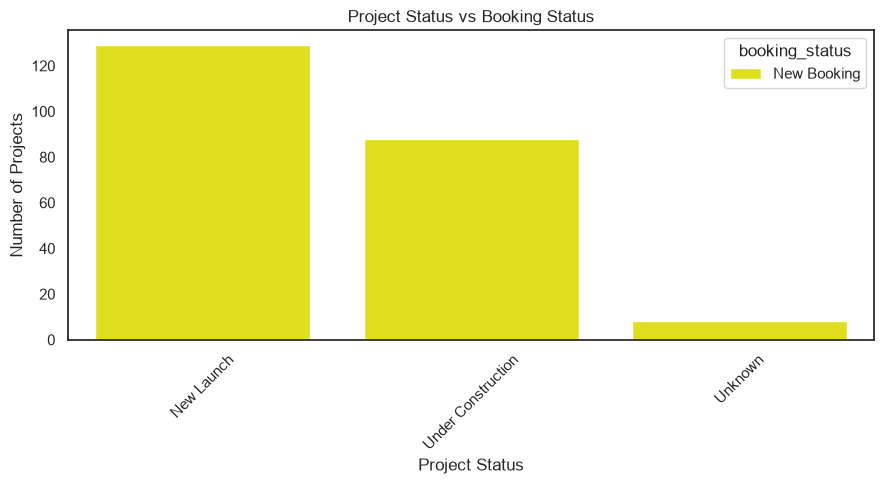

In [125]:
plt.figure(figsize=(9, 5))

sns.countplot(
    data=df,
    x="status",
    hue="booking_status",
    palette=[ "yellow"]
)

plt.title("Project Status vs Booking Status")
plt.xlabel("Project Status")
plt.ylabel("Number of Projects")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### 5. Location vs Builder — Crosstab Heatmap
Purpose: Identify which builders have the most listings in the selected locations.


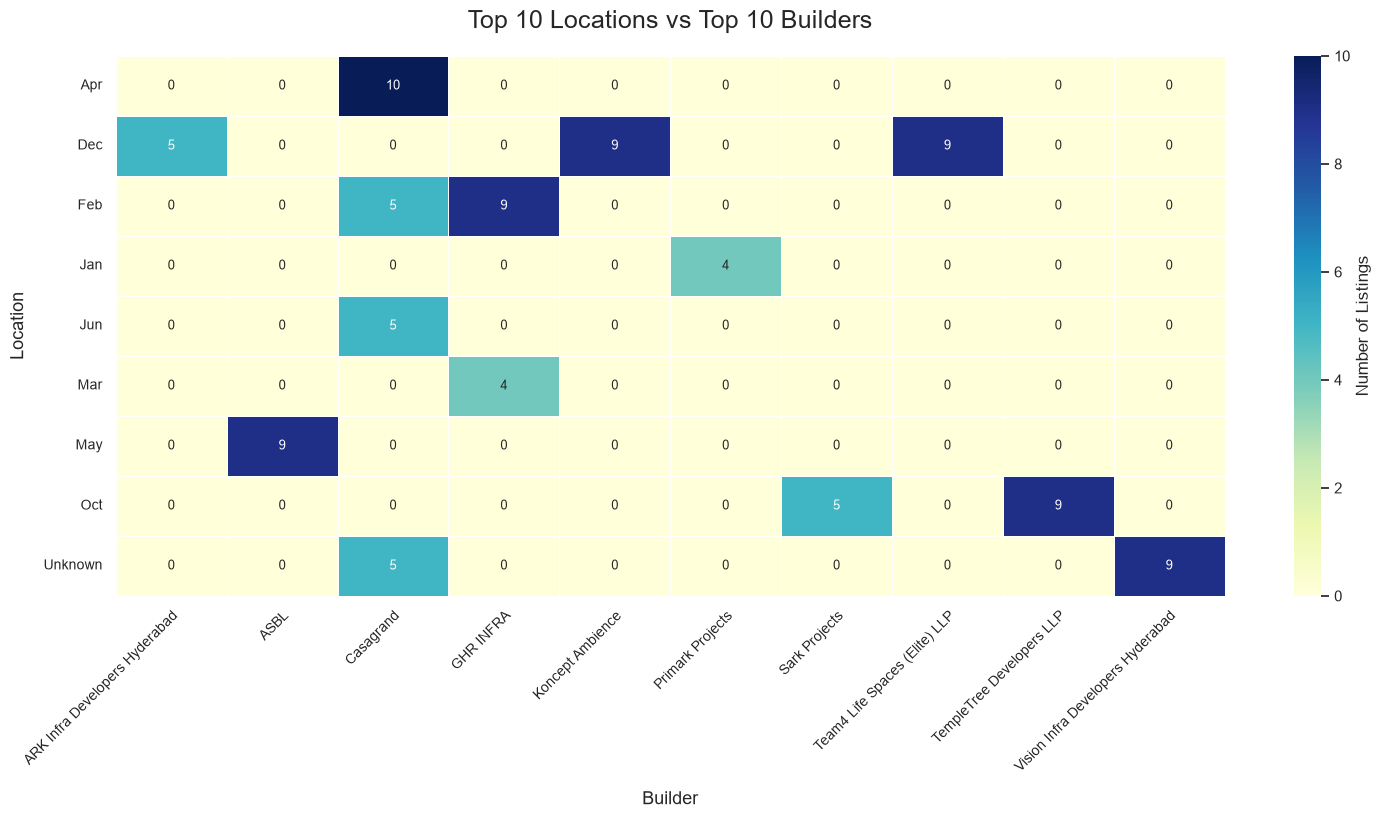

In [134]:
top_locations = df["location"].value_counts().head(10).index
top_builders = df["builder"].value_counts().head(10).index

temp = df[
    df["location"].isin(top_locations) &
    df["builder"].isin(top_builders)
]

cross_tab = pd.crosstab(
    temp["location"],
    temp["builder"]
)

fig, ax = plt.subplots(figsize=(18, 9))

sns.heatmap(
    cross_tab,
    annot=True,
    fmt="d",
    cmap="YlGnBu",
    linewidths=0.5,
    annot_kws={"size": 9},
    cbar_kws={"label": "Number of Listings"},
    ax=ax
)

ax.set_title("Top 10 Locations vs Top 10 Builders", fontsize=18, pad=20)
ax.set_xlabel("Builder", fontsize=13, labelpad=12)
ax.set_ylabel("Location", fontsize=13, labelpad=12)

# Prevent builder names from overlapping
ax.set_xticklabels(
    ax.get_xticklabels(),
    rotation=45,
    ha="right",
    rotation_mode="anchor",
    fontsize=10
)
ax.set_yticklabels(ax.get_yticklabels(), rotation=0, fontsize=10)

fig.subplots_adjust(bottom=0.30, left=0.18, right=0.95, top=0.90)
plt.show()

### Numerical vs Numerical analysis

In [47]:
print(df.select_dtypes(include="number").columns.tolist())

['completion_date', 'bhk', 'price', 'area_sqft']


## Price vs Area — Scatter Plot

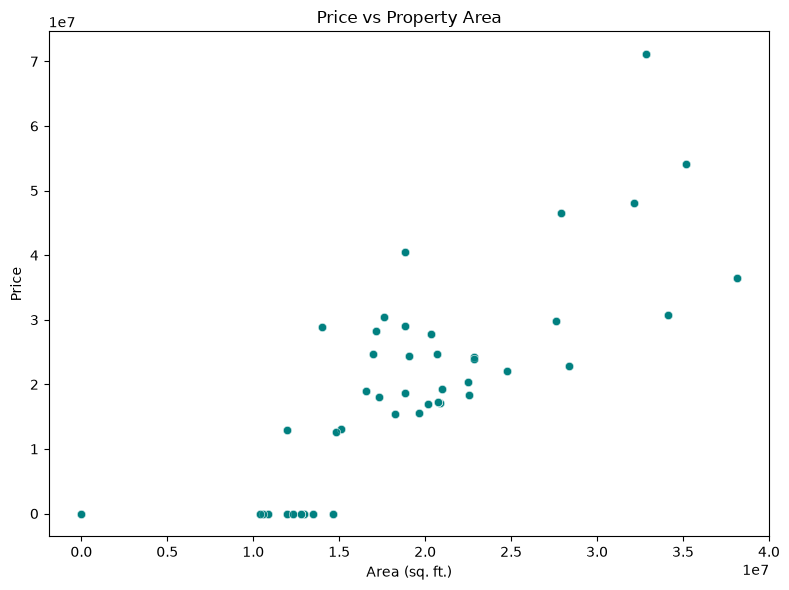

In [48]:
plt.figure(figsize=(8, 6))

sns.scatterplot(
    data=df,
    x="area_sqft",
    y="price",
    color="teal",
    alpha=0.7
)

plt.title("Price vs Property Area")
plt.xlabel("Area (sq. ft.)")
plt.ylabel("Price")
plt.tight_layout()
plt.show()

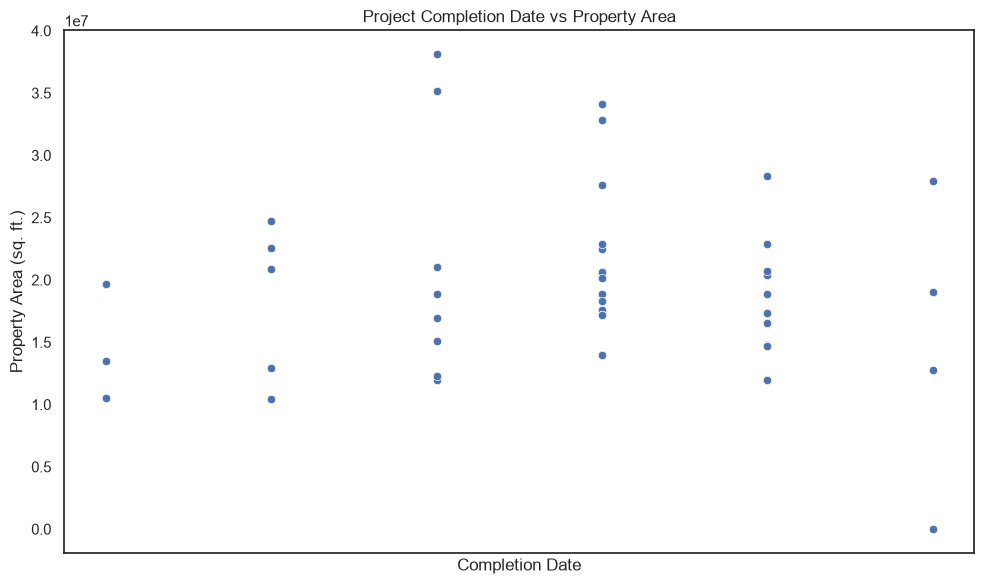

In [120]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Convert completion_date to datetime
df['completion_date'] = pd.to_datetime(
    df['completion_date'], errors='coerce'
)

# Remove missing values
plot_df = df[['completion_date', 'area_sqft']].dropna()

# Create scatter plot
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=plot_df,
    x='completion_date',
    y='area_sqft'
)

plt.title('Project Completion Date vs Property Area')
plt.xlabel('Completion Date')
plt.ylabel('Property Area (sq. ft.)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## Categorical VS Numerical 

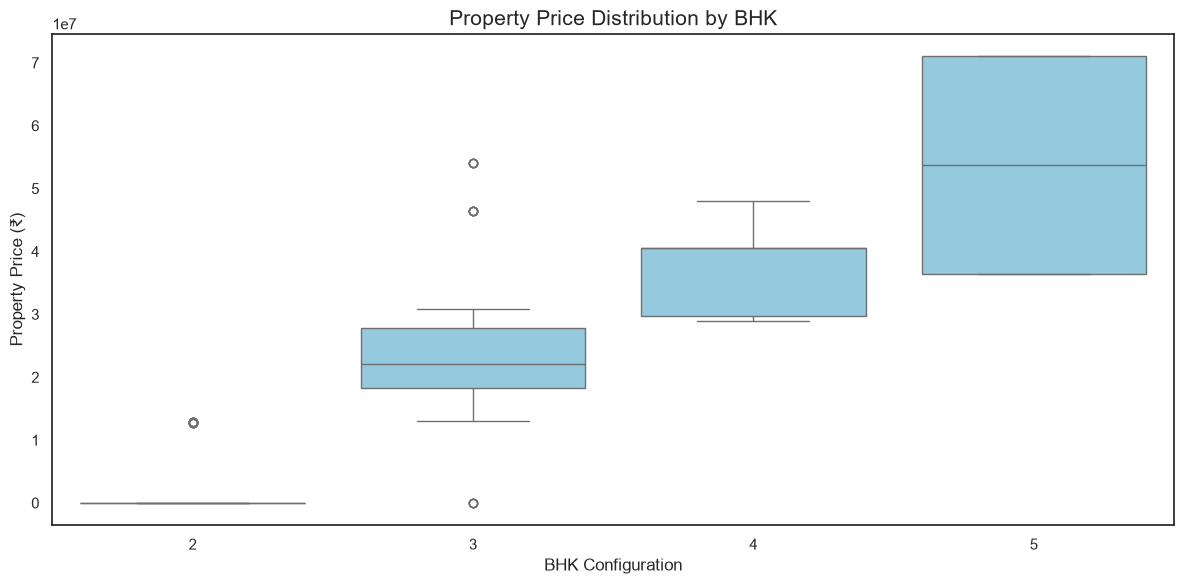

In [135]:

df["price"] = pd.to_numeric(df["price"], errors="coerce")

plt.figure(figsize=(12, 6))

sns.boxplot(
    data=df,
    x="bhk",
    y="price",
    color="skyblue"
)

plt.title("Property Price Distribution by BHK", fontsize=15)
plt.xlabel("BHK Configuration")
plt.ylabel("Property Price (₹)")
plt.tight_layout()
plt.show()


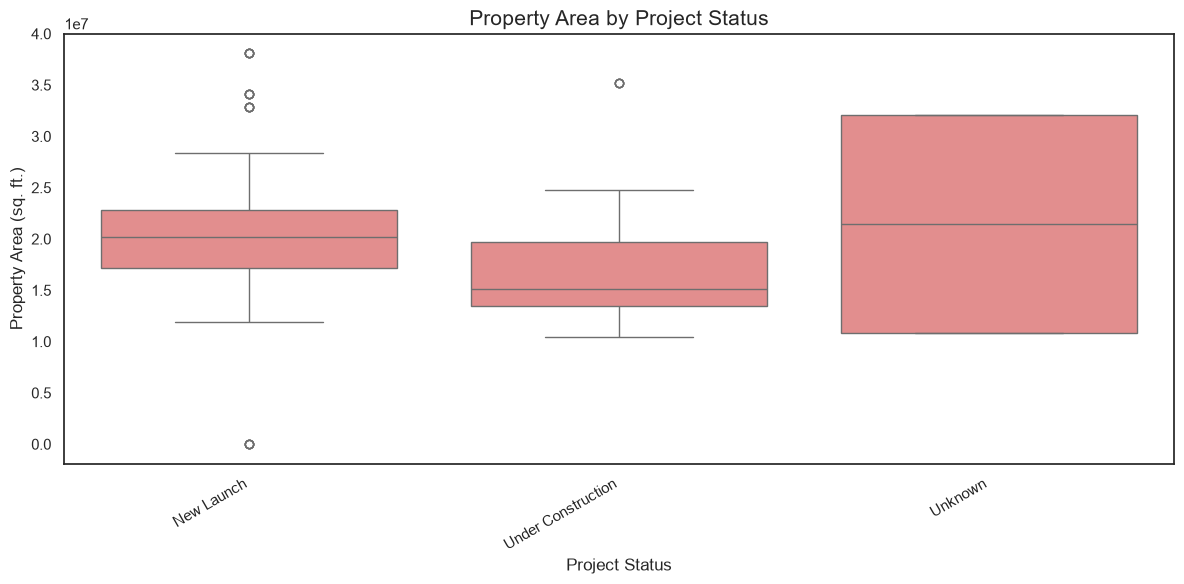

In [136]:

plt.figure(figsize=(12, 6))

sns.boxplot(
    data=df,
    x="status",
    y="area_sqft",
    color="lightcoral"
)

plt.title("Property Area by Project Status", fontsize=15)
plt.xlabel("Project Status")
plt.ylabel("Property Area (sq. ft.)")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()


## Numerical Correlation Heatmap

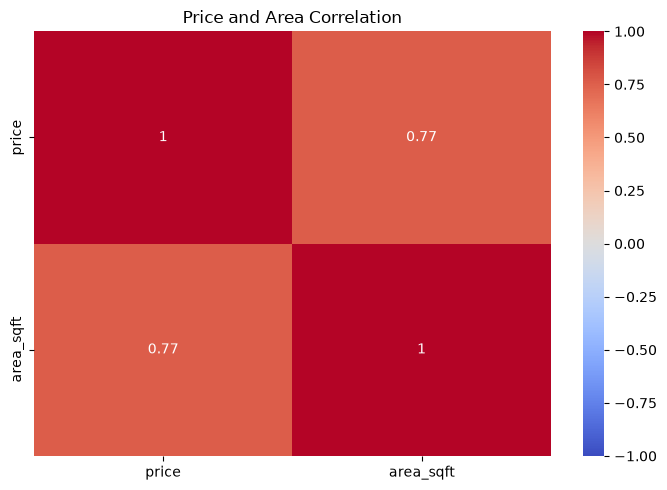

In [49]:
numeric_cols = ["price", "area_sqft"]

plt.figure(figsize=(7, 5))

sns.heatmap(
    df[numeric_cols].corr(),
    annot=True,
    cmap="coolwarm",
    vmin=-1,
    vmax=1df["price_category"] = pd.cut(
    df["price"],
    bins=[0, 5000000, 10000000, float("inf")],
    labels=["Affordable", "Mid-Range", "Premium"]
)

df[["price", "price_category"]].head()
)

plt.title("Price and Area Correlation")
plt.tight_layout()
plt.show()

In [61]:
df['Price_Category'] = pd.cut(
    df['price'],
    bins=[0, 5000000,  20000000, float('inf')],
    labels=['Budget', 'Premium', 'Luxury']
)

In [62]:
df['Price_Category'] 

0       Luxury
1       Luxury
2       Budget
3       Luxury
4      Premium
        ...   
220     Luxury
221    Premium
222     Luxury
223    Premium
224     Luxury
Name: Price_Category, Length: 225, dtype: category
Categories (3, object): ['Budget' < 'Premium' < 'Luxury']

In [63]:
df.head()

,project_name,status,completion_date,bhk,property_type,location,city,price,area_sqft,builder,rera_number,booking_status,offer,description,raw_details,rera_availability,price_category,Price_Category
0,GHR Trivana,New Launch,2030,4,Villa,"Feb, 2030 GHR Trivana NEW BOOKING 4, 5 BHK Vil...",Hyderabad,40500000.00,18852550,GHR INFRA,Not Available,New Booking,Not Available,"5 BHK Villa ₹4.62 Cr Spacious and elegant 4,5 ...","New Launch · Completion in Feb, 2030 GHR Triv...",RERA Number Available,Premium,Luxury
1,Vision Amnaya,New Launch,2029,3,Apartment,Unknown,Hyderabad,28200000.00,17152590,Vision Infra Developers Hyderabad,P02400011121,New Booking,Not Available,Finest 3 BHK apartments in Khajaguda available...,"New Launch · Completion in Dec, 2029 Vision A...",RERA Number Available,Premium,Luxury
2,URBANYARDS SHANGRILA,Under Construction,2030,2,Apartment,"Oct, 2030 URBANYARDS SHANGRILA NEW BOOKING 2, ...",Hyderabad,87.96,14662903,TempleTree Developers LLP,P02400010486,New Booking,Not Available,Not Available,"Under Construction · Completion in Oct, 2030 ...",RERA Number Available,Affordable,Budget
3,ASBL Broadway,New Launch,2030,3,Apartment,"May, 2030 ASBL Broadway NEW BOOKING 3 BHK Apar...",Hyderabad,27800000.00,20352650,ASBL,P02400009684,New Booking,1 OFFER,Not Available,"1 OFFER New Launch · Completion in May, 2030 ...",RERA Number Available,Premium,Luxury
4,Team4 Aria,New Launch,2030,3,Apartment,"Dec, 2030 Team4 Aria NEW BOOKING 3, 4 BHK Apar...",Hyderabad,19000000.00,16552650,Team4 Life Spaces (Elite) LLP,P02400010543,New Booking,Not Available,Not Available,"New Launch · Completion in Dec, 2030 Team4 Ar...",RERA Number Available,Premium,Premium


In [64]:
print(df.columns.tolist())

['project_name', 'status', 'completion_date', 'bhk', 'property_type', 'location', 'city', 'price', 'area_sqft', 'builder', 'rera_number', 'booking_status', 'offer', 'description', 'raw_details', 'rera_availability', 'price_category', 'Price_Category']


In [65]:
print(df.head())

           project_name              status  completion_date  bhk  \
0           GHR Trivana          New Launch             2030    4   
1         Vision Amnaya          New Launch             2029    3   
2  URBANYARDS SHANGRILA  Under Construction             2030    2   
3         ASBL Broadway          New Launch             2030    3   
4            Team4 Aria          New Launch             2030    3   

  property_type                                           location       city  \
0         Villa  Feb, 2030 GHR Trivana NEW BOOKING 4, 5 BHK Vil...  Hyderabad   
1     Apartment                                            Unknown  Hyderabad   
2     Apartment  Oct, 2030 URBANYARDS SHANGRILA NEW BOOKING 2, ...  Hyderabad   
3     Apartment  May, 2030 ASBL Broadway NEW BOOKING 3 BHK Apar...  Hyderabad   
4     Apartment  Dec, 2030 Team4 Aria NEW BOOKING 3, 4 BHK Apar...  Hyderabad   

         price  area_sqft                            builder    rera_number  \
0  40500000.00   18

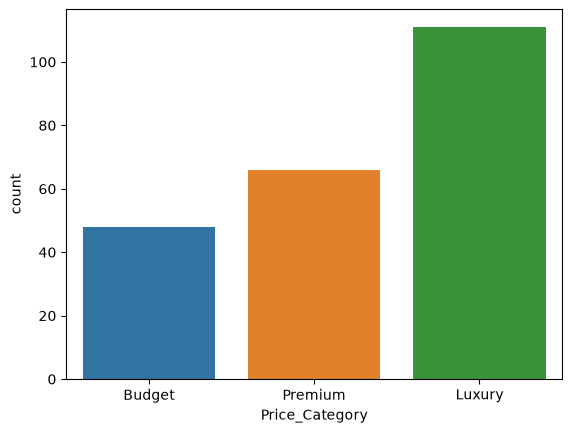

In [66]:
sns.countplot(x='Price_Category', data=df, palette='tab10')
plt.show()

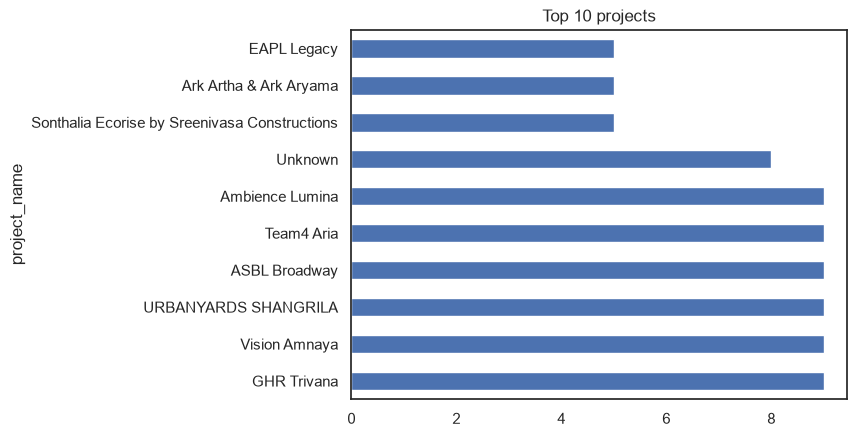

In [119]:
df['project_name'].value_counts().head(10).plot(kind='barh')
plt.title('Top 10 projects')
plt.show()

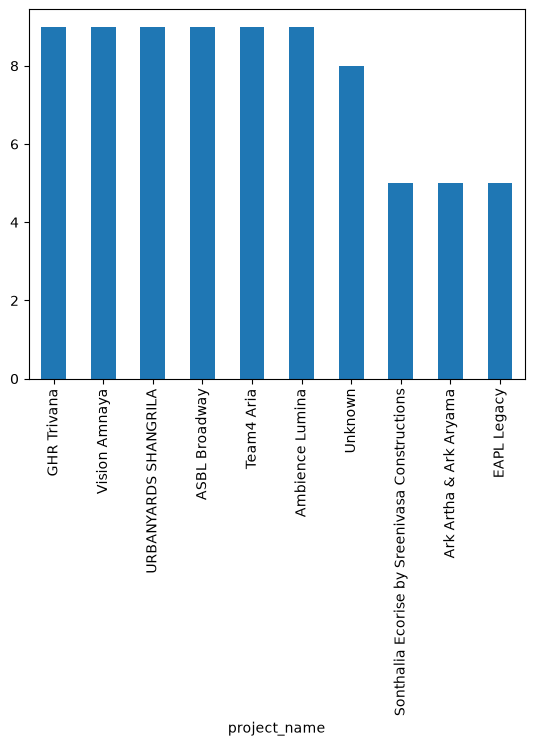

In [68]:
df['project_name'].value_counts().head(10).plot(kind='bar')
plt.show()

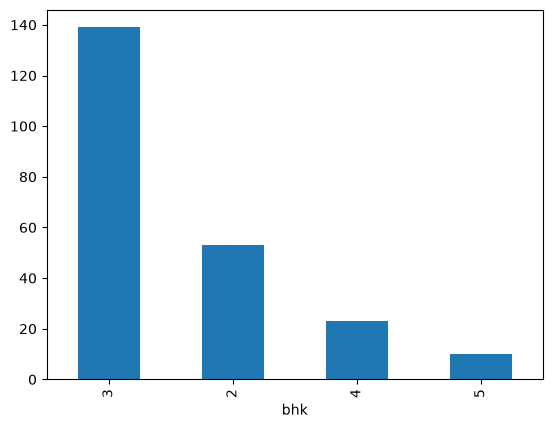

In [69]:
df['bhk'].value_counts().plot(kind='bar')
plt.show()

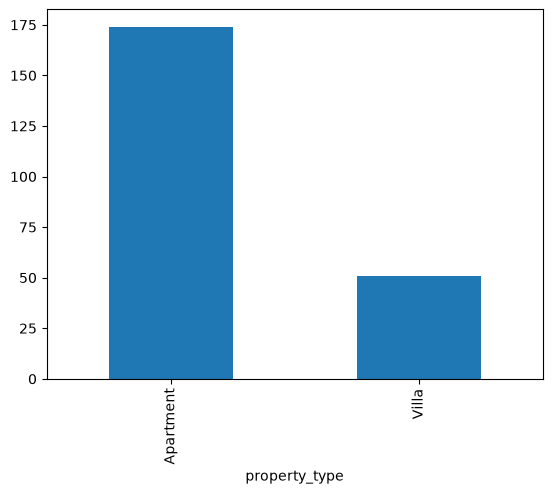

In [70]:
df['property_type'].value_counts().plot(kind='bar')
plt.show()

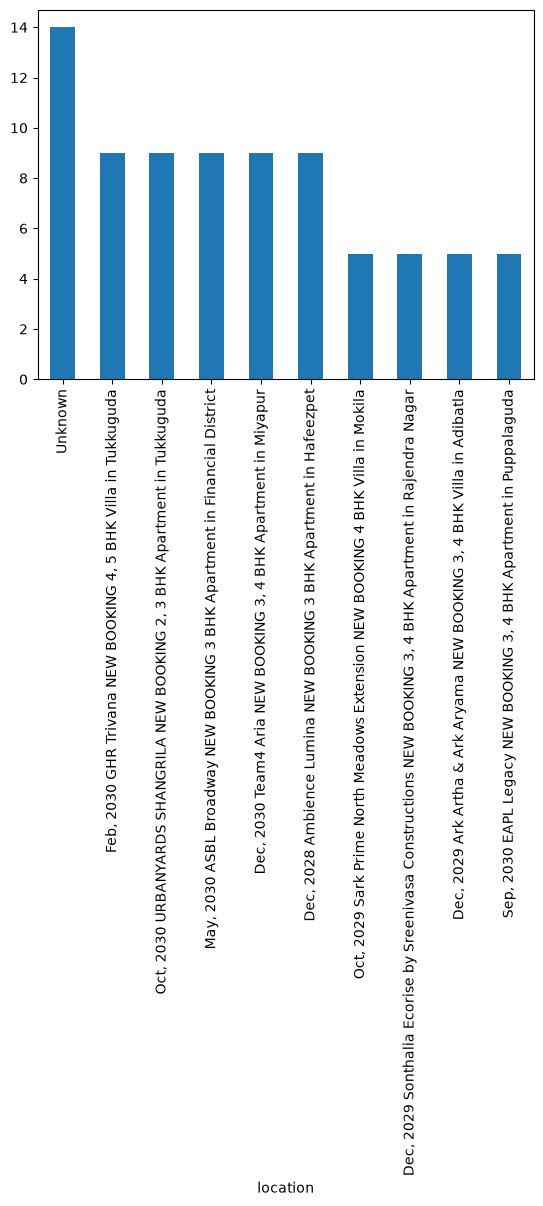

In [71]:
df['location'].value_counts().head(10).plot(kind='bar')
plt.show()

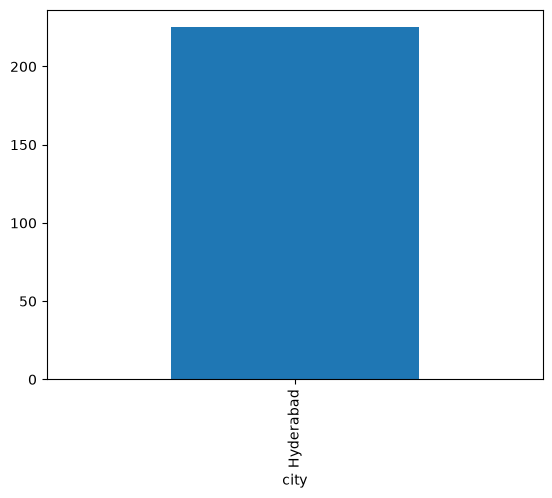

In [72]:
df['city'].value_counts().plot(kind='bar')
plt.show()

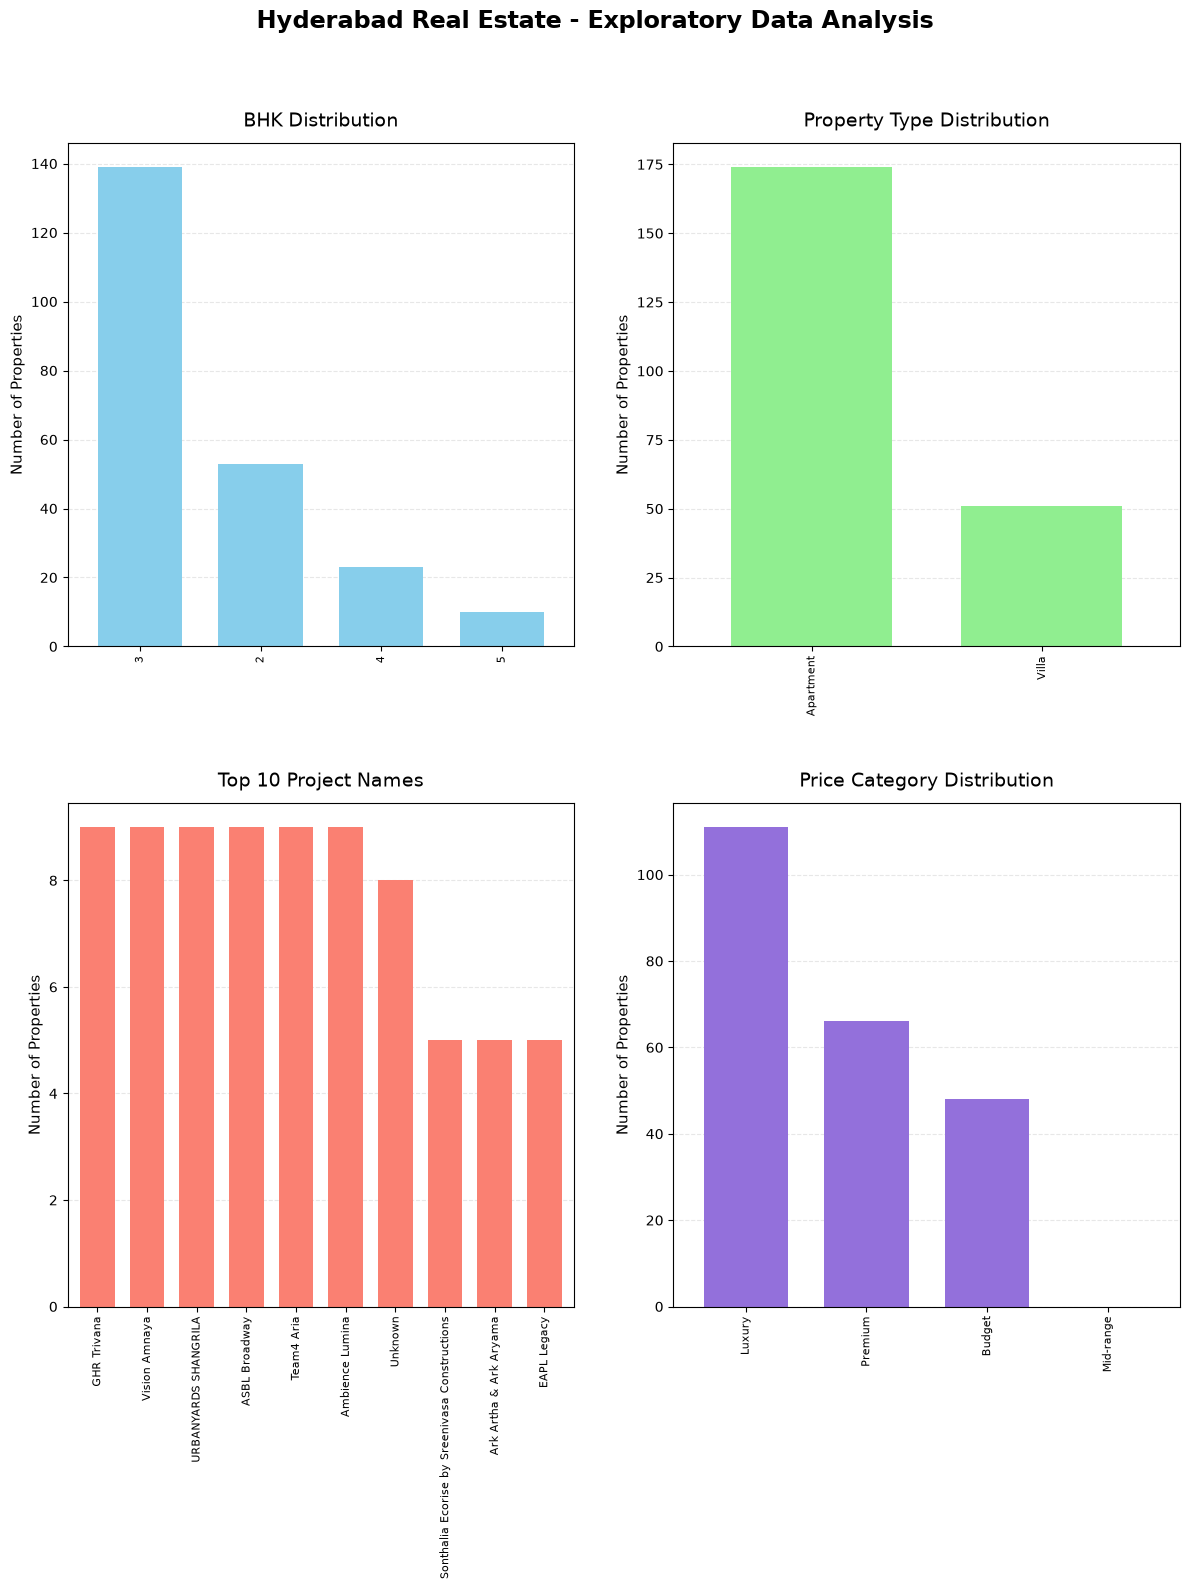

In [110]:
import pandas as pd
import matplotlib.pyplot as plt

# Create price categories
df['Price_Category'] = pd.cut(
    df['price'],
    bins=[0, 5000000, 10000000, 20000000, float('inf')],
    labels=['Budget', 'Mid-range', 'Premium', 'Luxury']
)

# Create a 2x2 subplot layout
fig, axes = plt.subplots(
    nrows=2,
    ncols=2,
    figsize=(12, 16)
)

# 1. BHK Distribution
df['bhk'].value_counts().plot(
    kind='bar',
    ax=axes[0, 0],
    color='skyblue',
    width=0.7
)
axes[0, 0].set_title('BHK Distribution', fontsize=14, pad=12)

# 2. Property Type Distribution
df['property_type'].value_counts().plot(
    kind='bar',
    ax=axes[0, 1],
    color='lightgreen',
    width=0.7
)
axes[0, 1].set_title('Property Type Distribution', fontsize=14, pad=12)

# 3. Top 10 Project Names
df['project_name'].value_counts().head(10).plot(
    kind='bar',
    ax=axes[1, 0],
    color='salmon',
    width=0.7
)
axes[1, 0].set_title('Top 10 Project Names', fontsize=14, pad=12)

# 4. Price Category Distribution
df['Price_Category'].value_counts().plot(
    kind='bar',
    ax=axes[1, 1],
    color='mediumpurple',
    width=0.7
)
axes[1, 1].set_title('Price Category Distribution', fontsize=14, pad=12)

# Format all graphs consistently
for ax in axes.flatten():
    ax.set_xlabel('')
    ax.set_ylabel('Number of Properties', fontsize=11)
    ax.tick_params(axis='x', labelrotation=90, labelsize=8)
    ax.tick_params(axis='y', labelsize=10)
    ax.grid(axis='y', linestyle='--', alpha=0.3)
    ax.set_axisbelow(True)

# Main title
plt.suptitle(
    'Hyderabad Real Estate - Exploratory Data Analysis',
    fontsize=17,
    fontweight='bold',
    y=0.99
)

# Adjust spacing
plt.tight_layout(rect=[0, 0, 1, 0.96], h_pad=4, w_pad=3)
plt.show()

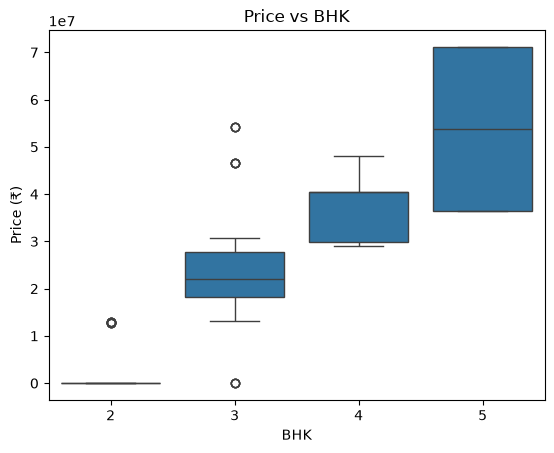

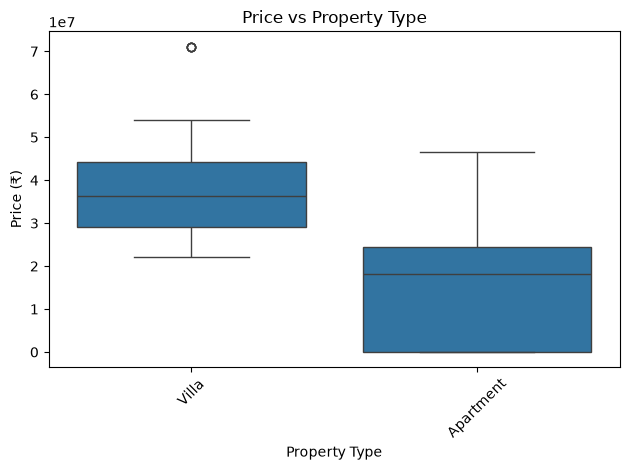

In [91]:
import seaborn as sns
import matplotlib.pyplot as plt

# Price vs BHK
sns.boxplot(x='bhk', y='price', data=df)
plt.title('Price vs BHK')
plt.xlabel('BHK')
plt.ylabel('Price (₹)')
plt.show()

# Price vs Property Type
sns.boxplot(x='property_type', y='price', data=df)
plt.title('Price vs Property Type')
plt.xlabel('Property Type')
plt.ylabel('Price (₹)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

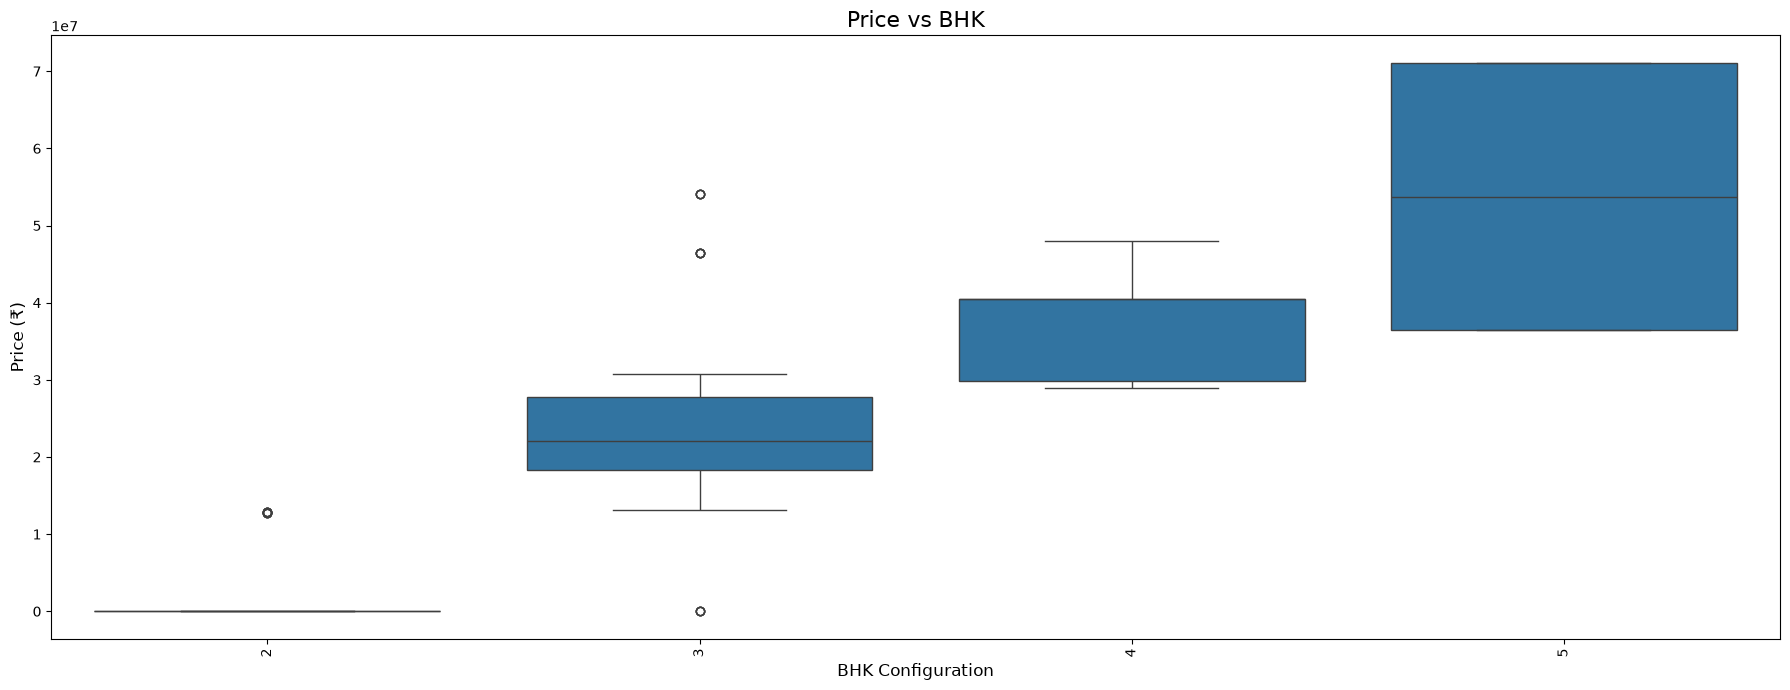

In [93]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(18, 7))

sns.boxplot(x='bhk', y='price', data=df)

plt.title('Price vs BHK', fontsize=16)
plt.xlabel('BHK Configuration', fontsize=12)
plt.ylabel('Price (₹)', fontsize=12)

plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

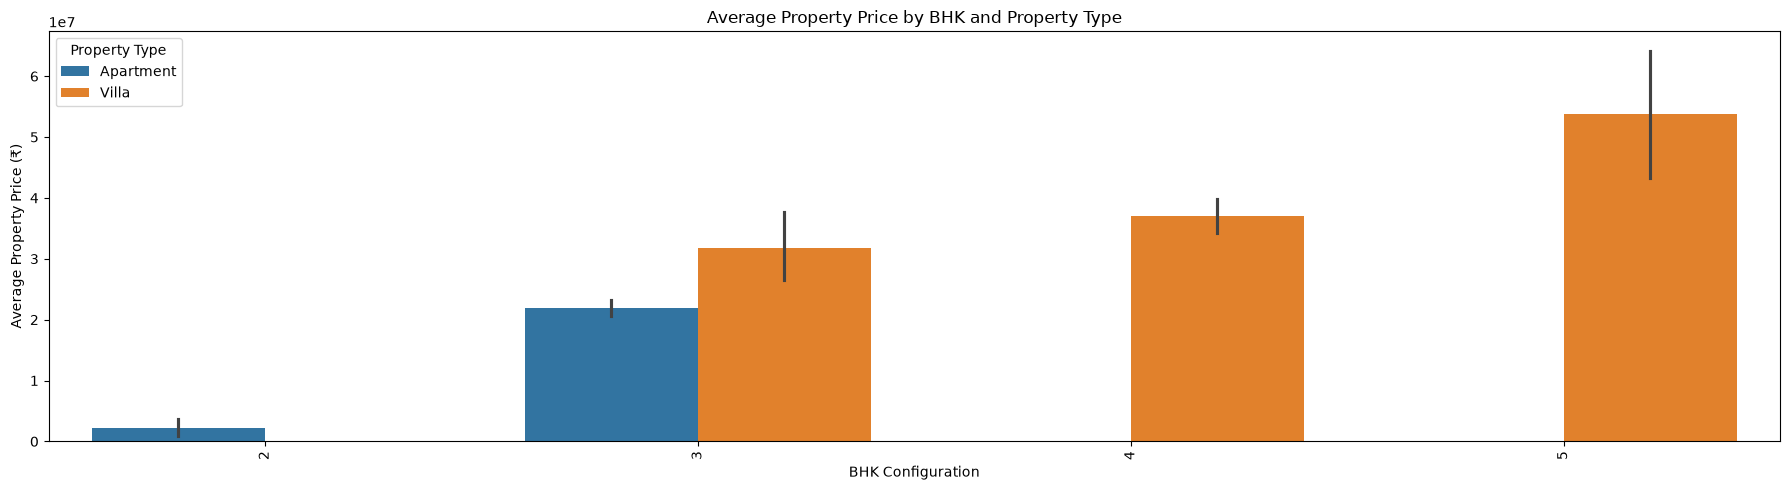

In [111]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(18, 5))

sns.barplot(
    x='bhk',
    y='price',
    hue='property_type',
    data=df,
    palette='tab10'
)

plt.title('Average Property Price by BHK and Property Type')
plt.xlabel('BHK Configuration')
plt.ylabel('Average Property Price (₹)')
plt.xticks(rotation=90)
plt.legend(title='Property Type')
plt.tight_layout()
plt.show()

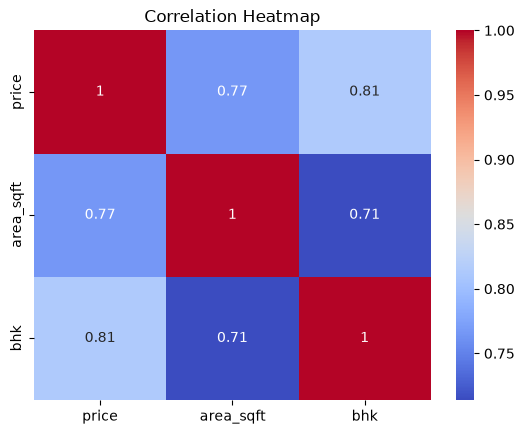

In [95]:
sns.heatmap(df[num_cols].corr(), annot=True, cmap='coolwarm')
plt.title('Correlation Heatmap')
plt.show()

In [103]:
# WHY hypothesis comes AFTER visualization?
# Because visuals tell us what looks true.
# Statistics tell us whether it is actually true.

# Hypothesis 1 (BHK vs Price)
# H0: BHK configuration has no significant difference in average property prices
# H1: At least one BHK configuration has a significantly different average price

# Hypothesis 2 (Area vs Price)
# H0: Property area has no significant linear correlation with price
# H1: Property area has a significant linear correlation with price

In [104]:
from scipy.stats import f_oneway

# Apply ANOVA: categorical vs numerical
groups = [
    df[df['bhk'] == bhk]['price'].dropna()
    for bhk in df['bhk'].dropna().unique()
]

# Remove empty groups
groups = [group for group in groups if len(group) > 0]

# Perform ANOVA
f_stat, p_value = f_oneway(*groups)

print("ANOVA F-statistic:", f_stat)
print("ANOVA p-value:", p_value)

if p_value < 0.05:
    print("Conclusion: Property prices differ significantly across BHK configurations.")
else:
    print("Conclusion: No statistically significant difference in average property prices across BHK configurations.")

ANOVA F-statistic: 153.58423747412888
ANOVA p-value: 8.53166677955306e-54
Conclusion: Property prices differ significantly across BHK configurations.


In [105]:
from scipy.stats import f_oneway

groups = [
    df[df['bhk'] == bhk]['price'].dropna()
    for bhk in df['bhk'].dropna().unique()
]

# Remove empty groups
groups = [group for group in groups if len(group) > 0]

f_stats, p_stats = f_oneway(*groups)

print("ANOVA F-statistic:", f_stats)
print("ANOVA p-value:", p_stats)

ANOVA F-statistic: 153.58423747412888
ANOVA p-value: 8.53166677955306e-54


In [106]:
if p_stats < 0.05:
    print("Reject H₀ → BHK configuration is significantly associated with property price")
else:
    print("Fail to reject H₀ → No statistically significant difference in average property prices across BHK configurations")

Reject H₀ → BHK configuration is significantly associated with property price


In [107]:
from scipy.stats import pearsonr

# Correlation between property area and price
data = df[['area_sqft', 'price']].dropna()

corr, p = pearsonr(data['area_sqft'], data['price'])

print("Correlation:", corr)
print("p-value:", p)

Correlation: 0.7655533178698057
p-value: 1.3461764841847718e-44


In [108]:
from scipy.stats import pearsonr

# Correlation between property area and price
data = df[['area_sqft', 'price']].dropna()

corr, p = pearsonr(data['area_sqft'], data['price'])

print("Correlation:", corr)
print("p-value:", p)

Correlation: 0.7655533178698057
p-value: 1.3461764841847718e-44


In [109]:
if p < 0.05:
    print("Reject H₀ → Property area has a statistically significant correlation with property price")
else:
    print("Fail to reject H₀ → No statistically significant correlation between property area and price")

Reject H₀ → Property area has a statistically significant correlation with property price
